# BDC Satria Data 2026 - Experiment v2 - MaxViT (hybrid conv-attention) + Greedy Model Soup

Kandidat upgrade dari `baseline_v1_convnext` (OOF macro F1 **0.9818**) untuk klasifikasi citra sampah 3 kelas: **0=Recyclable, 1=Electronic, 2=Organic** (juknis §4). Metrik kompetisi: **Macro-averaged F1-Score**.

**Dokumentasi backbone (wajib, juknis §5):**
- Model: `maxvit_rmlp_base_rw_224.sw_in12k_ft_in1k` dari pustaka `timm` (MaxViT-Base varian rw, ~115M parameter).
- Pretraining: supervised ImageNet-12k lalu fine-tune ImageNet-1k. Bobot tersedia publik di HF Hub (tanpa token) dan **tidak pernah dilatih dengan data train/test kompetisi ini**, memenuhi syarat transfer learning juknis §5.
- Mode pemakaian: **full fine-tune** (backbone dilatih penuh, kecuali 1 epoch warm-up head).
- Fallback bila OOM/terlalu lambat di T4: `coatnet_rmlp_2_rw_224.sw_in12k_ft_in1k` (~73M, hybrid juga; cukup ganti `CFG.MODEL_ID`).

**Apa yang berubah dari baseline v1, dan dasarnya:**
1. **Backbone hybrid conv-attention** menggantikan pure-CNN. Dasar: benchmark WaRP (Sayem et al., NCA 2025) menunjukkan MaxViT-T mengungguli ConvNeXt +1.98 poin akurasi pada data sampah heterogen, dan arah bias induktif yang berbeda membuat error v2 tidak berkorelasi penuh dengan v1 (modal untuk ensemble).
2. **Greedy model soup per fold** (Wortsman et al.; replikasi ICH arXiv 2603.02181): rata-rata bobot subset checkpoint terbaik yang dipilih greedy berdasarkan val macro F1. Biaya inferensi tetap satu model; worst case = checkpoint tunggal terbaik.
3. **Mixup/CutMix di GPU** (alpha kecil): menekan gap overfit v1 (train F1 0.999 vs val 0.98) tanpa menambah beban CPU DataLoader (pelajaran run v1: pipeline loader-bound).
4. **Fold identik dengan v1** (recompute deterministik + cross-check bila output v1 di-attach): audit near-duplicate 2026-07-12 memutus verdict NEGLIGIBLE (batas atas inflasi OOF 0.0007 < 0.002), jadi fold acuan v1 tetap sah dan OOF v1 vs v2 sah dibandingkan/diensemble.
5. Resolusi **tetap 224**: benchmark Garbage Dataset (arXiv 2602.10500, dijalankan di T4 x2) menunjukkan 384px memberi gain <1% dan kadang negatif; pilihan arsitektur jauh lebih berdampak.

**Aturan kompetisi yang dijaga notebook ini** (identik v1): data test hanya untuk prediksi akhir; tanpa data citra berlabel eksternal; tanpa metadata sebagai fitur (hash hanya untuk audit); submission mengikuti template persis, nama file memakai **kode kelompok** `submission_SD2026040000412.csv` (konfirmasi panitia di grup chat).

**Alur**: 0) Setup -> 1) Verifikasi struktur -> 2) EDA & cleaning -> 3) Fold identik v1 -> 4) Dataset & augmentasi -> 5) Model -> 6) Training + soup -> 7) OOF -> 8) Ensemble OOF (opsional) -> 9) Submission -> 10) Analisis error.

## 0. Setup & Konfigurasi

Deteksi environment otomatis (pola v1):
- **Kaggle**: dataset read-only di `/kaggle/input/.../bdc-2026-waste-classification-dataset`; seluruh output ke `/kaggle/working`. Single T4 (`USE_DATA_PARALLEL=False`, keputusan fix memory leak v1).
- **Lokal**: notebook dijalankan dari root project (sejajar `train/`, `test/`, `submission.csv`). Tambahan v2: dukungan **Apple Silicon (MPS)** untuk smoke test di Mac (fp32, tanpa GradScaler).

`SMOKE_TEST=True` (default) menjalankan seluruh pipeline pada subset kecil untuk verifikasi end-to-end. Run sebenarnya: set `SMOKE_TEST=False`, lalu *Save Version -> Save & Run All (Commit)* di Kaggle.

In [1]:
import copy
import glob
import hashlib
import math
import os
import platform
import random
import signal
import time
from contextlib import nullcontext
from datetime import date
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn.functional as F
from PIL import Image, ImageOps, ImageStat
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from timm.data import resolve_model_data_config
from torch import nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms
from tqdm.auto import tqdm

Image.MAX_IMAGE_PIXELS = None  # data kompetisi (trusted); foto besar jangan dianggap decompression bomb


def seed_everything(seed: int = 42, deterministic: bool = True):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic  # benchmark aktif = autotune conv, jauh lebih cepat


def rss_gb():
    """RSS proses saat ini dalam GB (Linux; NaN di platform lain), untuk observability RAM."""
    try:
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmRSS:"):
                    return int(line.split()[1]) / 1024 ** 2
    except Exception:
        pass
    return float("nan")


# Deteksi device: cuda (Kaggle/GPU) -> mps (Mac Apple Silicon, smoke test) -> cpu
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
N_GPUS = torch.cuda.device_count()
print("torch :", torch.__version__, "| timm :", timm.__version__)
print("device:", DEVICE, "| jumlah GPU CUDA:", N_GPUS)
for i in range(N_GPUS):
    props = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {props.name} | {props.total_memory / 1024**3:.1f} GB")

torch : 2.10.0+cu128 | timm : 1.0.26
device: cuda | jumlah GPU CUDA: 2
  GPU 0: Tesla T4 | 14.6 GB
  GPU 1: Tesla T4 | 14.6 GB


In [2]:
def running_on_kaggle() -> bool:
    return Path("/kaggle/input").exists() or bool(os.getenv("KAGGLE_KERNEL_RUN_TYPE"))


ON_KAGGLE = running_on_kaggle()
KAGGLE_DATA_ROOT = Path("/kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset")


class CFG:
    SEED = 42
    RUN_NAME = "experiment_v2_maxvit"
    GROUP_CODE = "SD2026040000412"  # kode kelompok; nama file submission = submission_<GROUP_CODE>.csv
                                    # (dikonfirmasi panitia di grup chat: pakai kode kelompok, bukan nama tim)

    ON_KAGGLE = ON_KAGGLE
    DATA_ROOT = KAGGLE_DATA_ROOT if ON_KAGGLE else Path.cwd()
    OUTPUT_ROOT = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
    TRAIN_DIR = DATA_ROOT / "train"
    TEST_DIR = DATA_ROOT / "test"
    TEMPLATE_PATH = DATA_ROOT / "submission.csv"
    EXP_DIR = OUTPUT_ROOT / "experiments" / RUN_NAME
    LOG_PATH = OUTPUT_ROOT / "experiments" / "EXPERIMENTS_LOG.md"
    SUBMISSION_DIR = OUTPUT_ROOT / "outputs"

    # Mapping resmi juknis §4, jangan diubah
    LABEL_NAMES = {0: "Recyclable", 1: "Electronic", 2: "Organic"}
    NUM_CLASSES = 3

    # Model v2: hybrid conv-attention, pretrain in12k -> in1k (dokumentasi di judul notebook)
    MODEL_ID = "maxvit_rmlp_base_rw_224.sw_in12k_ft_in1k"
    # Fallback bila OOM / >0.35 s/iter GPU-bound parah di T4: "coatnet_rmlp_2_rw_224.sw_in12k_ft_in1k"
    IMG_SIZE = 224
    DROP_PATH_RATE = 0.2  # lebih tinggi dari v1 (0.1): model lebih besar + gap overfit v1 nyata

    # Referensi v1 untuk perbandingan OOF dan ensemble (bagian 8-9)
    V1_RUN_NAME = "baseline_v1_convnext"
    V1_MODEL_ID = "convnextv2_base.fcmae_ft_in22k_in1k"
    V1_OOF_MACRO_F1 = 0.9818  # acuan; angka dari EXPERIMENTS_LOG entry 2026-07-05

    # Training
    N_FOLDS = 5
    TRAIN_FOLDS = [0, 1, 2, 3, 4]  # kalau proyeksi runtime > 8.5 jam: pecah [0,1,2] lalu [3,4] di dua commit
    EPOCHS = 10
    BATCH_SIZE = 32          # OOM di T4: turunkan ke 16 dan set GRAD_ACCUM_STEPS = 2 (batch efektif tetap 32)
    GRAD_ACCUM_STEPS = 1
    NUM_WORKERS = 4
    BACKBONE_LR = 2.5e-5     # attention block lebih sensitif LR daripada CNN; sedikit di bawah v1 (4e-5)
    HEAD_LR = 2.5e-4
    WEIGHT_DECAY = 1e-4
    FREEZE_BACKBONE_EPOCHS = 1
    EARLY_STOPPING_PATIENCE = 3
    FOCAL_GAMMA = 2.0
    LABEL_SMOOTHING = 0.05
    USE_VAL_TTA = True

    # Mixup/CutMix di GPU (nol beban CPU loader). MIX_PROB=0 menonaktifkan total.
    MIX_PROB = 0.5
    MIXUP_ALPHA = 0.2
    CUTMIX_ALPHA = 1.0

    # Greedy model soup per fold (arXiv 2603.02181): rata-rata bobot subset checkpoint top-K
    # yang dipilih greedy berdasarkan val macro F1 (tanpa TTA). Worst case = best single checkpoint.
    USE_GREEDY_SOUP = True
    SOUP_TOPK = 4

    # Ensemble dengan v1 (bagian 8-9). Jalan otomatis HANYA bila output notebook v1 di-attach
    # sebagai input (Add Input -> Your Work -> notebook baseline v1). Tanpa itu, di-skip rapi.
    ENSEMBLE_WITH_V1 = True

    HEARTBEAT_EVERY_BATCH = 50
    DECODE_TIMEOUT_S = 20
    CUDNN_DETERMINISTIC = False
    RESIZE_MP_THRESHOLD = 8_000_000
    RESIZE_MAX_SIDE = 1024
    MAX_DECODE_SIDE = 1024
    USE_DATA_PARALLEL = False  # keputusan final v1 (memory leak broadcast DataParallel); JANGAN dinyalakan lagi

    SMOKE_TEST = False
    SMOKE_PER_CLASS = 40
    SMOKE_TEST_IMAGES = 64


if CFG.SMOKE_TEST:
    CFG.TRAIN_FOLDS = [0]
    CFG.EPOCHS = 2  # 2 epoch supaya jalur soup (>= 2 kandidat checkpoint) ikut teruji
    CFG.BATCH_SIZE = 8
    # NUM_WORKERS=0 untuk Windows/macOS lokal (start method spawn); Kaggle/Linux pakai 2
    CFG.NUM_WORKERS = 0 if (platform.system() in ("Windows", "Darwin") and not ON_KAGGLE) else 2

_hint = ("Di Kaggle: pastikan dataset 'bdc-2026-waste-classification-dataset' sudah di-attach (Add Input)."
         if ON_KAGGLE else "Jalankan notebook dari root project (sejajar folder train/ dan test/).")
assert CFG.TRAIN_DIR.is_dir(), f"Folder train tidak ditemukan: {CFG.TRAIN_DIR}\n{_hint}"
assert CFG.TEST_DIR.is_dir(), f"Folder test tidak ditemukan: {CFG.TEST_DIR}\n{_hint}"

if not CFG.TEMPLATE_PATH.is_file():
    for cand in [CFG.DATA_ROOT / "template.csv", CFG.OUTPUT_ROOT / "submission.csv"]:
        if cand.is_file():
            CFG.TEMPLATE_PATH = cand
            break
assert CFG.TEMPLATE_PATH.is_file(), (
    f"Template submission tidak ditemukan di {CFG.DATA_ROOT / 'submission.csv'}. "
    "Di Kaggle: sertakan submission.csv di dataset, atau upload manual ke /kaggle/working.")

CFG.EXP_DIR.mkdir(parents=True, exist_ok=True)
CFG.SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(CFG.SEED, deterministic=CFG.CUDNN_DETERMINISTIC)
print("ENV :", "Kaggle" if ON_KAGGLE else "lokal")
print("DATA:", CFG.DATA_ROOT)
print("OUT :", CFG.OUTPUT_ROOT)
print("MODE:", "SMOKE_TEST (subset kecil, bukan hasil eksperimen)" if CFG.SMOKE_TEST else "FULL RUN")
print("EXP :", CFG.EXP_DIR, "| template:", CFG.TEMPLATE_PATH)
try:
    _mem = {l.split(":")[0]: int(l.split()[1]) for l in open("/proc/meminfo")
            if l.startswith(("MemTotal", "MemAvailable"))}
    print(f"RAM : total {_mem['MemTotal'] / 1024 ** 2:.1f}GB | available {_mem['MemAvailable'] / 1024 ** 2:.1f}GB")
except Exception:
    pass

ENV : Kaggle
DATA: /kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset
OUT : /kaggle/working
MODE: FULL RUN
EXP : /kaggle/working/experiments/experiment_v2_maxvit | template: /kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset/submission.csv
RAM : total 31.3GB | available 29.7GB


### Cek koneksi internet (wajib di Kaggle untuk unduh bobot pretrained)

Bobot MaxViT diunduh dari Hugging Face Hub oleh `timm` (publik, tanpa token). Di Kaggle, internet default **OFF**: Session options -> Internet -> ON.

In [3]:
import urllib.request


def internet_ok(url="https://huggingface.co", timeout=10):
    try:
        urllib.request.urlopen(url, timeout=timeout)
        return True
    except Exception:
        return False


if internet_ok():
    print("Koneksi ke huggingface.co OK, download bobot pretrained bisa berjalan.")
else:
    print("=" * 72)
    print("TIDAK ADA KONEKSI INTERNET ke huggingface.co.")
    print("Di Kaggle: Notebook -> Session options -> Internet -> ON, lalu jalankan ulang.")
    print("Jika bobot pretrained sudah ada di cache, cell ini boleh di-skip.")
    print("=" * 72)
    raise RuntimeError("Internet nonaktif, ikuti instruksi di atas.")

Koneksi ke huggingface.co OK, download bobot pretrained bisa berjalan.


### Observability: Weights & Biases (opsional) + heartbeat print

Pelajaran run v1: progress intra-epoch wajib terlihat di log commit Kaggle. Heartbeat print (`flush=True`) tiap 50 batch menampilkan s/iter dan RSS (+delta), W&B opsional via Kaggle Secrets `WANDB_API_KEY`.

In [4]:
try:
    import wandb
    WANDB_AVAILABLE = True
except ImportError:
    wandb = None
    WANDB_AVAILABLE = False

WANDB_PROJECT = "bdc-satria-data-2026"


def wandb_login():
    if not WANDB_AVAILABLE:
        print("Paket wandb tidak terinstall, logging W&B nonaktif.")
        return False
    api_key = os.getenv("WANDB_API_KEY")
    if not api_key and CFG.ON_KAGGLE:
        try:
            from kaggle_secrets import UserSecretsClient
            api_key = UserSecretsClient().get_secret("WANDB_API_KEY")
        except Exception as e:
            print("Kaggle Secrets WANDB_API_KEY tidak bisa diambil:", repr(e))
    if not api_key:
        print("WANDB_API_KEY tidak tersedia. Di Kaggle: Add-ons -> Secrets -> 'WANDB_API_KEY'.")
        return False
    try:
        wandb.login(key=api_key)
        return True
    except Exception as e:
        print("Login W&B gagal:", repr(e))
        return False


WANDB_ENABLED = wandb_login()
print("W&B:", "AKTIF" if WANDB_ENABLED else "nonaktif (heartbeat tetap tampil via print)")

Kaggle Secrets WANDB_API_KEY tidak bisa diambil: BackendError("Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 125761498 and label WANDB_API_KEY.'], 'error': {'code': 5}, 'wasSuccessful': False}.")
WANDB_API_KEY tidak tersedia. Di Kaggle: Add-ons -> Secrets -> 'WANDB_API_KEY'.
W&B: nonaktif (heartbeat tetap tampil via print)


## 1. Verifikasi Struktur Data

Label **tidak diasumsikan**: struktur folder discan via kode. Ekspektasi juknis §3-§4: `train/` 26.527 citra dalam subfolder per kelas, `test/` 1.458 file bernomor 1..1458 sesuai template, mapping `0=Recyclable, 1=Electronic, 2=Organic`.

In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Struktur train/ (os.walk, maksimum 2 level):")
for root, dirs, files in os.walk(CFG.TRAIN_DIR):
    depth = len(Path(root).relative_to(CFG.TRAIN_DIR).parts)
    if depth > 1:
        continue
    imgs = [f for f in files if Path(f).suffix.lower() in IMAGE_EXTS]
    print(f"  {Path(root).relative_to(CFG.DATA_ROOT)} | subdir={sorted(dirs)} | n_gambar={len(imgs)} | contoh={imgs[:2]}")

class_dirs = sorted([p for p in CFG.TRAIN_DIR.iterdir() if p.is_dir()])
assert class_dirs, f"Tidak ada subfolder kelas di {CFG.TRAIN_DIR}"

dir_mapping = {}
for d in class_dirs:
    code_str, _, name = d.name.partition("_")
    assert code_str.isdigit() and name, f"Nama subfolder tidak berpola '<kode>_<NamaKelas>': {d.name}"
    dir_mapping[int(code_str)] = (name, d)

assert set(dir_mapping) == set(CFG.LABEL_NAMES), f"Kode kelas folder {sorted(dir_mapping)} != juknis {sorted(CFG.LABEL_NAMES)}"
for label_code, (name, _) in dir_mapping.items():
    assert name == CFG.LABEL_NAMES[label_code], (
        f"Nama kelas folder '{name}' (kode {label_code}) != juknis '{CFG.LABEL_NAMES[label_code]}', verifikasi manual dulu!")
print("\nMapping folder -> label terverifikasi sesuai juknis:", {k: v[0] for k, v in sorted(dir_mapping.items())})

train_rows = []
for label_code, (name, d) in sorted(dir_mapping.items()):
    for p in sorted(d.iterdir()):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            train_rows.append({"relpath": str(p.relative_to(CFG.DATA_ROOT)), "path": str(p),
                               "class_name": name, "label": label_code})
train_df = pd.DataFrame(train_rows)
print(f"Total gambar train: {len(train_df)} (juknis: 26.527)")

test_paths = sorted([p for p in CFG.TEST_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS])
subdirs_test = [p for p in CFG.TEST_DIR.iterdir() if p.is_dir()]
assert not subdirs_test, f"Tidak diduga: test/ punya subfolder {subdirs_test}"
test_id_to_path = {}
for p in test_paths:
    assert p.stem.isdigit(), f"Nama file test bukan angka murni: {p.name}"
    tid = int(p.stem)
    assert tid not in test_id_to_path, f"id test duplikat: {tid}"
    test_id_to_path[tid] = p
print(f"Total gambar test : {len(test_id_to_path)} (juknis: 1.458) | id min={min(test_id_to_path)} max={max(test_id_to_path)}")
assert set(test_id_to_path) == set(range(1, len(test_id_to_path) + 1)), "id test tidak kontinu 1..N"

Struktur train/ (os.walk, maksimum 2 level):
  train | subdir=['0_Recyclable', '1_Electronic', '2_Organic'] | n_gambar=0 | contoh=[]
  train/0_Recyclable | subdir=[] | n_gambar=9999 | contoh=['005463.jpg', '000304.jpg']
  train/1_Electronic | subdir=[] | n_gambar=3961 | contoh=['000304.jpg', '001940.jpg']
  train/2_Organic | subdir=[] | n_gambar=12567 | contoh=['011035.jpg', '010011.jpg']

Mapping folder -> label terverifikasi sesuai juknis: {0: 'Recyclable', 1: 'Electronic', 2: 'Organic'}
Total gambar train: 26527 (juknis: 26.527)
Total gambar test : 1458 (juknis: 1.458) | id min=1 max=1458


In [6]:
template_df = pd.read_csv(CFG.TEMPLATE_PATH)
display(template_df.head(3))
assert list(template_df.columns) == ["id", "predicted"], f"Kolom template tidak sesuai: {list(template_df.columns)}"
assert len(template_df) == len(test_id_to_path), f"Baris template ({len(template_df)}) != jumlah file test ({len(test_id_to_path)})"
assert template_df["id"].is_unique, "id template tidak unik"
assert set(template_df["id"]) == set(test_id_to_path), "id template != id file test"

TEMPLATE_ID_ORDER = template_df["id"].tolist()
print(f"Template OK: {len(TEMPLATE_ID_ORDER)} id | awal {TEMPLATE_ID_ORDER[:5]} | akhir {TEMPLATE_ID_ORDER[-5:]}")

,id,predicted
0,1,NaN
1,2,NaN
2,3,NaN


Template OK: 1458 id | awal [1, 2, 3, 4, 5] | akhir [1454, 1455, 1456, 1457, 1458]


In [7]:
# Saat SMOKE_TEST: pangkas train agar seluruh pipeline terverifikasi cepat (termasuk CPU/MPS lokal).
# Hasil smoke BUKAN hasil eksperimen: tidak dicatat ke EXPERIMENTS_LOG dan tidak menghasilkan submission.
if CFG.SMOKE_TEST:
    sampled_idx = []
    for _, g in train_df.groupby("label"):
        sampled_idx.extend(g.sample(min(len(g), CFG.SMOKE_PER_CLASS), random_state=CFG.SEED).index)
    train_df = train_df.loc[sorted(sampled_idx)].reset_index(drop=True)
    print(f"SMOKE_TEST: train_df dipangkas menjadi {len(train_df)} baris ({CFG.SMOKE_PER_CLASS}/kelas)")
else:
    print("FULL RUN: memakai seluruh train_df:", len(train_df), "baris")

FULL RUN: memakai seluruh train_df: 26527 baris


## 2. EDA & Data Cleaning

EDA penuh (distribusi, resolusi, brightness/contrast, sampel visual) sudah didokumentasikan di notebook v1 dan hasilnya tidak berubah (dataset sama). Di sini dipertahankan pemeriksaan yang MEMPENGARUHI pipeline: distribusi kelas, integritas decode, dan dedup exact.

In [8]:
class_counts = train_df["class_name"].value_counts().reindex([CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)])
display(class_counts.to_frame("count").assign(pct=lambda d: (100 * d["count"] / d["count"].sum()).round(2)))
print(f"Imbalance ratio (max/min): {class_counts.max() / class_counts.min():.2f}x")

,count,pct
class_name,,
Recyclable,9999,37.69
Electronic,3961,14.93
Organic,12567,47.37


Imbalance ratio (max/min): 3.17x


> ### Insights
> Electronic tetap kelas minoritas (15%, imbalance 3.2x). Macro F1 memberi bobot sama per kelas, jadi `WeightedRandomSampler` + focal alpha `1/sqrt(count)` dipertahankan dari v1. Catatan OOF v1: justru **Recyclable** kelas terlemah (F1 0.9751, presisi 0.9719) dengan kebocoran utama ke/dari Organic; Electronic malah tertinggi (0.9891). Mixup/CutMix lintas kelas diharapkan menghaluskan boundary R-O tersebut.

### Integritas file: sha256 + validasi decode dengan timeout (jalur persis DataLoader)

In [9]:
# Proteksi decode-hang: validasi memakai JALUR YANG SAMA dengan DataLoader
# (draft + exif_transpose + convert RGB), timeout per file via SIGALRM (Linux/Kaggle/macOS).
SCAN_VER = 3  # sama dengan v1: cache scan_train.csv bisa dipakai lintas notebook bila tersedia


class DecodeTimeout(Exception):
    pass


def _decode_alarm(signum, frame):
    raise DecodeTimeout()


HAS_SIGALRM = hasattr(signal, "SIGALRM")
if not HAS_SIGALRM:
    print("PERINGATAN: platform tanpa SIGALRM (Windows), timeout decode nonaktif.")


def scan_files(records, cache_path):
    """Satu pass per file: sha256(bytes) + decode penuh + ukuran piksel. Cache (relpath, size, SCAN_VER)."""
    cache = {}
    if Path(cache_path).exists():
        cdf = pd.read_csv(cache_path)
        if "scan_ver" in cdf.columns:
            cache = {(r.relpath, int(r.size_bytes)): dict(r._asdict())
                     for r in cdf.itertuples(index=False) if int(r.scan_ver) == SCAN_VER}
    rows, n_cached = [], 0
    if HAS_SIGALRM:
        signal.signal(signal.SIGALRM, _decode_alarm)
    for rec in tqdm(records, desc=f"scan {Path(cache_path).stem}"):
        p = Path(rec["path"])
        size = p.stat().st_size
        key = (rec["relpath"], size)
        if key in cache:
            rows.append(cache[key])
            n_cached += 1
            continue
        row = {"relpath": rec["relpath"], "size_bytes": size, "sha256": None, "scan_ver": SCAN_VER,
               "decode_ok": False, "width": -1, "height": -1, "error": ""}
        try:
            data = p.read_bytes()
            row["sha256"] = hashlib.sha256(data).hexdigest()
            if HAS_SIGALRM:
                signal.alarm(CFG.DECODE_TIMEOUT_S)
            try:
                with Image.open(BytesIO(data)) as img:
                    row["width"], row["height"] = img.size
                    img.draft("RGB", (CFG.MAX_DECODE_SIDE, CFG.MAX_DECODE_SIDE))
                    decoded = ImageOps.exif_transpose(img).convert("RGB")
            finally:
                if HAS_SIGALRM:
                    signal.alarm(0)
            row["decode_ok"] = True
        except DecodeTimeout:
            row["error"] = f"DecodeTimeout: decode lebih dari {CFG.DECODE_TIMEOUT_S}s, dikeluarkan dari pipeline"
        except Exception as e:
            row["error"] = f"{type(e).__name__}: {e}"[:200]
        rows.append(row)
        cache[key] = row
    pd.DataFrame(list(cache.values())).to_csv(cache_path, index=False)
    out = pd.DataFrame(rows)
    print(f"  {len(out)} file | {n_cached} dari cache | gagal decode/timeout={int((~out['decode_ok'].astype(bool)).sum())}")
    return out


train_scan = scan_files(train_df.to_dict("records"), CFG.EXP_DIR / "scan_train.csv")
test_records = [{"relpath": str(p.relative_to(CFG.DATA_ROOT)), "path": str(p)} for p in test_paths]
test_scan = scan_files(test_records, CFG.EXP_DIR / "scan_test.csv")

scan scan_train:   0%|          | 0/26527 [00:00<?, ?it/s]

  26527 file | 0 dari cache | gagal decode/timeout=0


scan scan_test:   0%|          | 0/1458 [00:00<?, ?it/s]

  1458 file | 0 dari cache | gagal decode/timeout=0


In [10]:
train_scan["decode_ok"] = train_scan["decode_ok"].astype(bool)
test_scan["decode_ok"] = test_scan["decode_ok"].astype(bool)
corrupt_train = train_scan[~train_scan["decode_ok"]]
corrupt_test = test_scan[~test_scan["decode_ok"]]
if len(corrupt_train):
    print("File train corrupt (di-drop dari training):")
    display(corrupt_train)
if len(corrupt_test):
    print("PERHATIAN: file test corrupt, tetap wajib diprediksi; inference memakai fallback gambar hitam:")
    display(corrupt_test)
if corrupt_train.empty and corrupt_test.empty:
    print("Tidak ada file corrupt.")

train_df = train_df.merge(train_scan[["relpath", "sha256", "decode_ok", "width", "height"]], on="relpath", validate="1:1")
n_before = len(train_df)
train_df = train_df[train_df["decode_ok"]].drop(columns=["decode_ok"]).reset_index(drop=True)
print(f"train_df: {n_before} -> {len(train_df)} setelah drop corrupt")

Tidak ada file corrupt.
train_df: 26527 -> 26527 setelah drop corrupt


### Duplikat exact (sha256), status audit near-duplicate, dan antrean review

Kebijakan identik v1: duplikat same-label disimpan 1 salinan; grup **mixed-label** dikeluarkan dari training dan masuk antrean review manual (`duplicates_mixed_label_review.csv`); overlap exact train-test hanya dilaporkan (pemanfaatannya di sisi prediksi, bagian 9).

**Status audit near-duplicate (2026-07-12, `tools/near_dup_audit_local.py` + `experiments/near_dup_audit/`):** pHash 64-bit Hamming <= 4 menemukan 436 grup near-dup (910 file, 3.44% populasi); di bawah StratifiedKFold acak ~742 baris OOF (2.8%) berada di grup yang menyeberang fold. Batas ATAS inflasi OOF (asumsi terburuk semua baris itu benar hanya karena kembaran) adalah **0.0007 macro F1**, di bawah ambang keputusan 0.002, sehingga verdict **NEGLIGIBLE**: fold acuan v1 tetap sah dan dipakai ulang di notebook ini. 7 grup near-dup beda label (19 file) masuk antrean review manual terpisah (`near_dup_mixed_label_review.csv`); tidak ada relabel otomatis (keputusan berbasis paper 2407.05528 dan 2410.07689).

In [11]:
grp = train_df.groupby("sha256")
group_size = grp["relpath"].transform("size")
n_labels_in_group = grp["label"].transform("nunique")
dup_mask = group_size > 1
mixed_mask = n_labels_in_group > 1

print(f"Grup duplikat exact dalam train: {train_df.loc[dup_mask, 'sha256'].nunique()} grup ({int(dup_mask.sum())} file)")
print(f"  di antaranya mixed-label     : {train_df.loc[mixed_mask, 'sha256'].nunique()} grup ({int(mixed_mask.sum())} file)")

review_df = train_df[mixed_mask].sort_values(["sha256", "relpath"]).copy()
if len(review_df):
    review_df["group_id"] = review_df.groupby("sha256").ngroup()
    review_df["group_size"] = review_df.groupby("sha256")["relpath"].transform("size")
    review_df["labels_in_group"] = review_df.groupby("sha256")["class_name"].transform(lambda s: "|".join(sorted(set(s))))
    members = review_df.groupby("sha256")["relpath"].agg(list).to_dict()
    review_df["other_members"] = ["|".join(m for m in members[h] if m != r)
                                  for h, r in zip(review_df["sha256"], review_df["relpath"])]
    review_df["corrected_label"] = ""
review_path = CFG.EXP_DIR / "duplicates_mixed_label_review.csv"
review_df.to_csv(review_path, index=False)
print(f"Antrean review manual relabeling disimpan: {review_path} ({len(review_df)} baris)")

n_before = len(train_df)
train_df = train_df[~mixed_mask]
train_df = train_df.sort_values("relpath").drop_duplicates("sha256").reset_index(drop=True)
print(f"train_df: {n_before} -> {len(train_df)} setelah dedup")

test_hashes = set(test_scan.loc[test_scan["decode_ok"], "sha256"])
overlap = train_df[train_df["sha256"].isin(test_hashes)]
print(f"\nOverlap exact train<->test: {len(overlap)} file train identik dengan file test (LAPORAN SAJA, tidak ada tindakan).")

Grup duplikat exact dalam train: 62 grup (124 file)
  di antaranya mixed-label     : 1 grup (2 file)
Antrean review manual relabeling disimpan: /kaggle/working/experiments/experiment_v2_maxvit/duplicates_mixed_label_review.csv (2 baris)
train_df: 26527 -> 26464 setelah dedup

Overlap exact train<->test: 97 file train identik dengan file test (LAPORAN SAJA, tidak ada tindakan).


### Pre-resize salinan gambar raksasa (>=8MP)

Dipertahankan dari v1 (fix insiden OOM): 233 gambar >=8MP (semuanya Electronic, kelas yang justru di-oversample sampler) dibuatkan salinan sisi maksimum 1024px di `train_resized/`. File asli tidak diubah; `Image.draft` juga terpasang permanen di dataset sebagai lapisan pengaman kedua. Fail-fast assertion menghentikan run bila substitusi path gagal.

In [12]:
t_resize = time.time()
big_mask = (train_df["width"].astype(int) * train_df["height"].astype(int)) >= CFG.RESIZE_MP_THRESHOLD
resized_root = CFG.OUTPUT_ROOT / "train_resized"
n_big = int(big_mask.sum())
sample_before = train_df.loc[big_mask, "path"].head(3).tolist()
print(f"pre-resize: {n_big} gambar >= {CFG.RESIZE_MP_THRESHOLD / 1e6:.0f}MP terdeteksi", flush=True)
n_new = 0
for idx in tqdm(train_df.index[big_mask], desc="pre-resize"):
    dst = resized_root / train_df.at[idx, "relpath"]
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        img = Image.open(train_df.at[idx, "path"])
        img.draft("RGB", (CFG.RESIZE_MAX_SIDE, CFG.RESIZE_MAX_SIDE))
        img = ImageOps.exif_transpose(img).convert("RGB")
        img.thumbnail((CFG.RESIZE_MAX_SIDE, CFG.RESIZE_MAX_SIDE), Image.Resampling.LANCZOS)
        if dst.suffix.lower() in {".jpg", ".jpeg"}:
            img.save(dst, quality=95)
        else:
            img.save(dst)
        n_new += 1
    train_df.at[idx, "path"] = str(dst)

if n_big:
    redirected = train_df.loc[big_mask, "path"]
    assert redirected.str.startswith(str(resized_root)).all(), \
        "pre-resize GAGAL: sebagian path masih menunjuk file asli raksasa"
    _missing = [p for p in redirected if not Path(p).is_file()]
    assert not _missing, f"pre-resize GAGAL: {len(_missing)} salinan tidak ada di disk, contoh: {_missing[:3]}"
    with Image.open(redirected.iloc[0]) as _im:
        assert max(_im.size) <= CFG.RESIZE_MAX_SIDE, f"pre-resize GAGAL: salinan masih berukuran {_im.size}"
    print("bukti redirect | SEBELUM:", sample_before[0])
    print("bukti redirect | SESUDAH:", redirected.iloc[0])
assert not train_df.loc[~big_mask, "path"].str.startswith(str(resized_root)).any(), \
    "path gambar normal ikut teralihkan, tidak seharusnya"
print(f"pre-resize SELESAI: {n_big} dialihkan ({n_new} baru dibuat) dalam {time.time() - t_resize:.1f}s | RSS {rss_gb():.1f}GB", flush=True)

pre-resize: 233 gambar >= 8MP terdeteksi


pre-resize:   0%|          | 0/233 [00:00<?, ?it/s]

bukti redirect | SEBELUM: /kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset/train/1_Electronic/000022.jpeg
bukti redirect | SESUDAH: /kaggle/working/train_resized/train/1_Electronic/000022.jpeg
pre-resize SELESAI: 233 dialihkan (233 baru dibuat) dalam 30.3s | RSS 1.0GB


## 3. Fold: identik dengan baseline v1 (syarat sah ensemble OOF)

OOF v2 hanya sah dibandingkan/diensemble dengan OOF v1 kalau **fold split identik**. Dua mekanisme:
1. **Recompute deterministik**: pipeline di atas (sort relpath -> scan -> dedup -> `StratifiedKFold(5, shuffle, seed 42)`) identik byte-per-byte dengan v1, pada dataset Kaggle yang sama, sehingga assignment fold yang dihasilkan identik dengan `folds.csv` run v1.
2. **Cross-check eksplisit** (hanya jalan bila output notebook v1 di-attach: *Add Input -> Your Work -> notebook baseline v1*): `folds.csv` v1 dimuat dan di-assert sama persis. Kalau tidak di-attach, recompute tetap dipakai dan determinisme dicatat.

> ### Insights
> Audit near-duplicate memvonis NEGLIGIBLE (inflasi maksimum 0.0007), jadi split lama TIDAK diganti group-aware. Konsekuensi yang diterima sadar: ~2.8% baris OOF berada di grup near-dup lintas fold; angka OOF dibaca dengan toleransi itu. Keuntungannya: OOF v1 (sudah ada) langsung sah untuk evaluasi ensemble tanpa retrain v1.

In [13]:
skf = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
train_df["fold"] = -1
for fold, (_, val_idx) in enumerate(skf.split(train_df["relpath"], train_df["label"])):
    train_df.loc[val_idx, "fold"] = fold
assert (train_df["fold"] >= 0).all()

# Cross-check dengan folds.csv run v1 (bila output notebook v1 di-attach sebagai input)
v1_folds_cands = [p for p in glob.glob("/kaggle/input/**/folds.csv", recursive=True) if CFG.V1_RUN_NAME in p] + \
    [str(CFG.OUTPUT_ROOT / "experiments" / CFG.V1_RUN_NAME / "folds.csv")]
v1_folds_path = next((p for p in v1_folds_cands if Path(p).is_file()), None)
FOLDS_CROSSCHECKED = False
if CFG.SMOKE_TEST:
    print("SMOKE_TEST: cross-check folds v1 dilewati (train_df subset).")
elif v1_folds_path:
    _v1 = pd.read_csv(v1_folds_path)[["relpath", "fold"]].rename(columns={"fold": "fold_v1"})
    _m = train_df.merge(_v1, on="relpath", how="left", validate="one_to_one")
    assert _m["fold_v1"].notna().all(), (
        f"folds.csv v1 ({v1_folds_path}) tidak meng-cover semua baris train_df: data version berbeda. STOP.")
    assert (_m["fold"] == _m["fold_v1"].astype(int)).all(), (
        "FOLD BERBEDA dari run v1! Recompute tidak identik; JANGAN lanjut, ensemble OOF tidak akan sah.")
    FOLDS_CROSSCHECKED = True
    print(f"Cross-check LULUS: fold identik dengan {v1_folds_path}")
else:
    print("folds.csv v1 tidak di-attach; memakai recompute deterministik (pipeline+seed identik v1).")
    print("Untuk cross-check eksplisit: Add Input -> Your Work -> notebook baseline v1.")

folds_path = CFG.EXP_DIR / "folds.csv"
train_df[["relpath", "class_name", "label", "fold"]].to_csv(folds_path, index=False)
print("Fold assignment disimpan:", folds_path)
display(pd.crosstab(train_df["fold"], train_df["class_name"]))
if not CFG.SMOKE_TEST:
    _expect = {(0, "Electronic"): 786, (1, "Electronic"): 786, (2, "Electronic"): 786,
               (3, "Electronic"): 786, (4, "Electronic"): 787}
    _ct = pd.crosstab(train_df["fold"], train_df["class_name"])
    for (f, c), v in _expect.items():
        assert int(_ct.loc[f, c]) == v, f"Crosstab fold {f}/{c} = {_ct.loc[f, c]}, run v1 = {v}. Fold drift!"
    print("Sanity crosstab vs run v1 (2026-07-05): cocok.")

Cross-check LULUS: fold identik dengan /kaggle/input/datasets/riantamaputra/baseline-v1-convnext/experiments/baseline_v1_convnext/folds.csv
Fold assignment disimpan: /kaggle/working/experiments/experiment_v2_maxvit/folds.csv


class_name,Electronic,Organic,Recyclable
fold,,,
0,786,2509,1998
1,786,2509,1998
2,786,2509,1998
3,786,2509,1998
4,787,2508,1997


Sanity crosstab vs run v1 (2026-07-05): cocok.


## 4. Dataset, Augmentasi Online, Loss, dan Mixup/CutMix

Augmentasi berbasis PIL **identik v1** (RandomResizedCrop 0.65-1.0, HFlip, ColorJitter brightness/contrast agresif hue=0, blur nonaktif): parameter ini sudah dituning untuk throughput CPU Kaggle dan variasi exposure data. Regularisasi tambahan dipindah ke GPU:

- **Mixup (alpha 0.2) / CutMix (alpha 1.0)**, dipilih acak 50:50, diterapkan dengan peluang `MIX_PROB=0.5` per batch **setelah** batch sampai di GPU, jadi nol beban tambahan untuk DataLoader (pelajaran v1: run loader-bound).
- Loss tetap `FocalLossWithSmoothing` alpha `1/sqrt(count)` + `WeightedRandomSampler` (pola ver34 yang terbukti); untuk batch ter-mix, loss dihitung `lam * loss(y_a) + (1-lam) * loss(y_b)`.

> ### Insights
> Bukti literatur untuk pilihan ini: resep fine-tune pada data noisy di arXiv 2603.02181 memakai HFlip+Mixup+CutMix; sementara S2-FracMix (2606.25784) kehilangan keunggulannya vs mixup biasa justru pada backbone pretrained kuat, jadi tidak diadopsi. Alpha kecil (0.2) dipilih agar distribusi input tidak bergeser jauh pada rezim akurasi 0.98.

### Modularisasi dataset (bdc_lib_v2.py)

Modul terpisah agar kelas dataset picklable oleh DataLoader worker `spawn` (Windows/macOS). Isi `WasteDataset`/transform **identik bdc_lib.py v1**; nama file dibedakan supaya tidak saling menimpa saat kedua notebook berada di direktori yang sama.

In [14]:
%%writefile bdc_lib_v2.py
"""Dataset dan transform untuk BDC Satria Data 2026 (experiment v2).

Isi identik dengan bdc_lib.py milik baseline v1 (JANGAN ubah tanpa eksperimen baru);
file terpisah hanya agar tidak menimpa modul v1 saat dua notebook satu direktori.
"""
import torch
from PIL import Image, ImageOps
from torch.utils.data import Dataset
from torchvision import transforms


class WasteDataset(Dataset):
    def __init__(self, df, transform, with_target=True, safe_mode=False, img_size=224, max_decode_side=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.with_target = with_target
        self.safe_mode = safe_mode  # True untuk test: file gagal decode -> gambar hitam (tetap wajib diprediksi)
        self.img_size = img_size
        self.max_decode_side = max_decode_side

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        try:
            image = Image.open(row["path"])
            if self.max_decode_side:
                # JPEG: decoder membaca langsung pada resolusi tereduksi; file raksasa TIDAK PERNAH
                # dimuat resolusi penuh ke RAM (terukur v1: 569MB -> 54MB per file 48MP).
                image.draft("RGB", (self.max_decode_side, self.max_decode_side))
            image = ImageOps.exif_transpose(image).convert("RGB")
        except Exception:
            if not self.safe_mode:
                raise
            image = Image.new("RGB", (self.img_size, self.img_size))
        sample = {"image": self.transform(image)}
        if self.with_target:
            sample["target"] = torch.tensor(int(row["label"]), dtype=torch.long)
        return sample


def build_transforms(img_size, mean, std):
    """Augmentasi online. Parameter identik baseline v1 (jangan ubah tanpa eksperimen baru)."""
    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.65, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        # hue=0: konversi warna per gambar mahal di CPU (penyebab GPU idle di run awal v1)
        transforms.RandomApply([transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.25, hue=0.0)], p=0.8),
        # GaussianBlur tetap nonaktif (beban CPU tinggi); regularisasi tambahan v2 ada di mixup/cutmix GPU
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    eval_transform = transforms.Compose([
        transforms.Resize(int(img_size * 1.14)),
        transforms.CenterCrop(img_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    return train_transform, eval_transform


def worker_init_fn(worker_id):
    """1 thread intra-op per worker: cegah oversubscription CPU (pelajaran run v1)."""
    torch.set_num_threads(1)

Writing bdc_lib_v2.py


In [15]:
import importlib

import bdc_lib_v2
importlib.reload(bdc_lib_v2)
from bdc_lib_v2 import WasteDataset, build_transforms, worker_init_fn

print("modul dataset:", bdc_lib_v2.__file__)

# mean/std mengikuti konfigurasi pretrained timm model v2 (probe tanpa mengunduh bobot)
probe = timm.create_model(CFG.MODEL_ID, pretrained=False, num_classes=0)
data_cfg = resolve_model_data_config(probe)
MEAN, STD = tuple(data_cfg["mean"]), tuple(data_cfg["std"])
assert data_cfg["input_size"][-1] == CFG.IMG_SIZE, f"Input size model {data_cfg['input_size']} != CFG.IMG_SIZE"
del probe
print("normalisasi:", MEAN, STD)

train_transform, eval_transform = build_transforms(CFG.IMG_SIZE, MEAN, STD)
print(train_transform)

modul dataset: /kaggle/working/bdc_lib_v2.py
normalisasi: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.65, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomApply(
    p=0.8
    ColorJitter(brightness=(0.6, 1.4), contrast=(0.6, 1.4), saturation=(0.75, 1.25), hue=None)
)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)


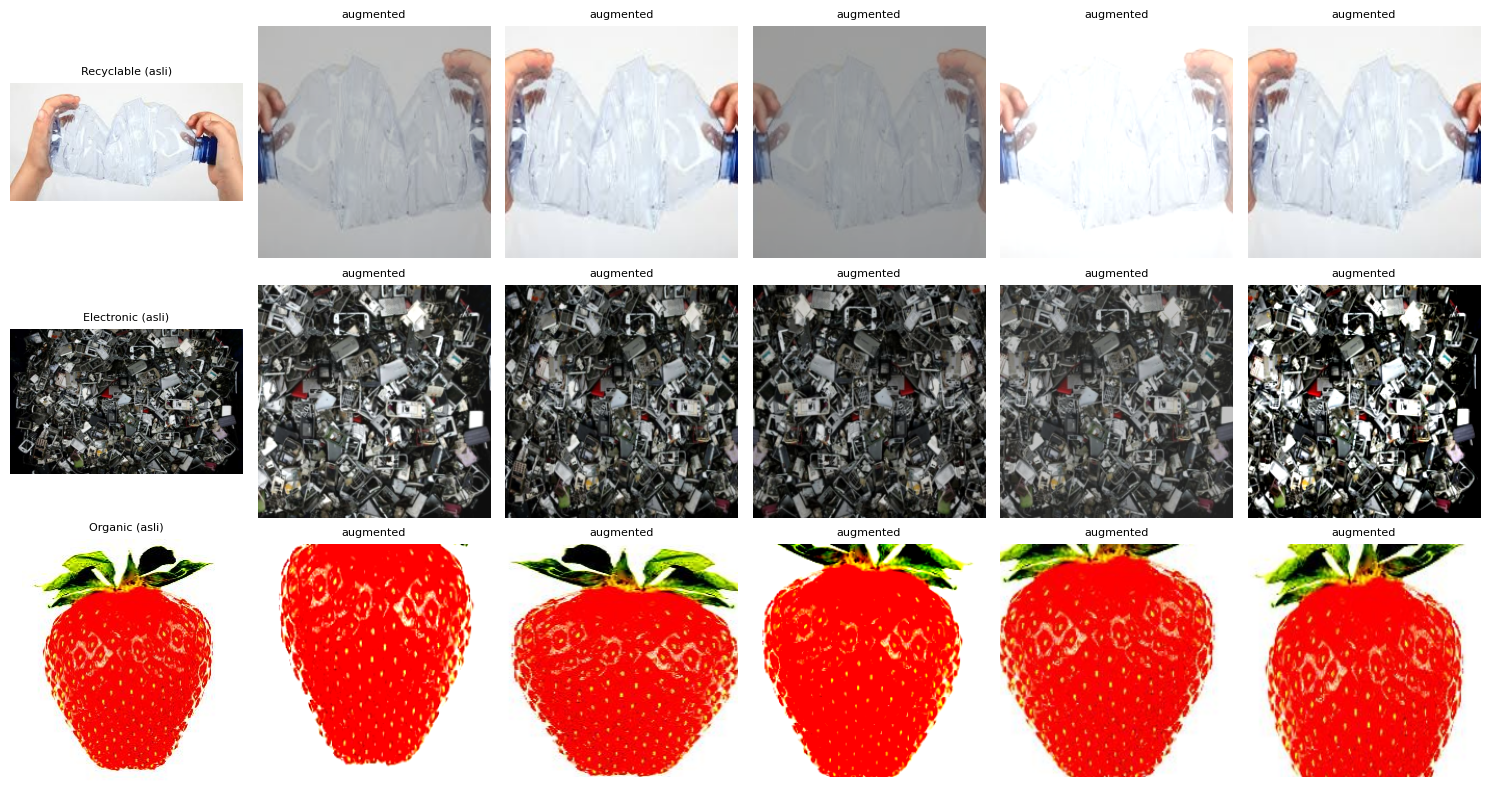

In [16]:
# Sanity check visual augmentasi: 1 gambar per kelas, 5 variasi augmented
viz_tf = transforms.Compose(train_transform.transforms[:-2])  # tanpa ToTensor/Normalize
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for i in range(CFG.NUM_CLASSES):
    row = train_df[train_df["label"] == i].iloc[0]
    img = ImageOps.exif_transpose(Image.open(row["path"])).convert("RGB")
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{row['class_name']} (asli)", fontsize=8)
    for j in range(1, 6):
        axes[i, j].imshow(viz_tf(img))
        axes[i, j].set_title("augmented", fontsize=8)
    for j in range(6):
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

In [17]:
class FocalLossWithSmoothing(nn.Module):
    """Pola ref/ver34_clean_end_to_end.ipynb, identik v1."""

    def __init__(self, num_classes, alpha, gamma, smoothing):
        super().__init__()
        self.gamma = gamma
        self.smoothing = smoothing
        self.num_classes = num_classes
        self.alpha = alpha

    def forward(self, inputs, targets):
        with torch.no_grad():
            true_dist = torch.zeros_like(inputs)
            true_dist.fill_(self.smoothing / (self.num_classes - 1))
            true_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        log_p = F.log_softmax(inputs, dim=-1)
        p = log_p.exp()
        focal_weight = (1.0 - p).pow(self.gamma)
        focal_weight = focal_weight * self.alpha[targets].view(-1, 1)
        return (-focal_weight * true_dist * log_p).sum(dim=-1).mean()


def build_criterion(fold_train_df):
    counts = fold_train_df["label"].value_counts()
    weights = torch.tensor([1.0 / math.sqrt(counts.get(c, 1)) for c in range(CFG.NUM_CLASSES)],
                           dtype=torch.float32, device=DEVICE)
    weights /= weights.mean()
    return FocalLossWithSmoothing(CFG.NUM_CLASSES, alpha=weights, gamma=CFG.FOCAL_GAMMA,
                                  smoothing=CFG.LABEL_SMOOTHING), weights


def build_sampler(fold_train_df, seed):
    counts = fold_train_df["label"].value_counts().to_dict()
    sample_weights = fold_train_df["label"].map(lambda c: 1.0 / counts[c]).to_numpy(dtype=np.float64).copy()
    gen = torch.Generator()
    gen.manual_seed(seed)
    return WeightedRandomSampler(torch.DoubleTensor(sample_weights), num_samples=len(sample_weights),
                                 replacement=True, generator=gen)


def mixup_cutmix_batch(images, targets):
    """Mixup/CutMix DI GPU setelah batch tiba (nol beban CPU loader).
    Return: images (mungkin dimodifikasi in-place untuk cutmix), dan mix_info=(y_a, y_b, lam) atau None."""
    if CFG.MIX_PROB <= 0 or float(torch.rand(())) > CFG.MIX_PROB or images.size(0) < 2:
        return images, None
    use_cutmix = float(torch.rand(())) < 0.5
    alpha = CFG.CUTMIX_ALPHA if use_cutmix else CFG.MIXUP_ALPHA
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(images.size(0), device=images.device)
    if use_cutmix:
        H, W = images.shape[-2:]
        r = math.sqrt(1.0 - lam)
        cw, ch = int(W * r), int(H * r)
        cx, cy = np.random.randint(W), np.random.randint(H)
        x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, W)
        y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, H)
        if x2 > x1 and y2 > y1:
            images[:, :, y1:y2, x1:x2] = images[perm, :, y1:y2, x1:x2]
            lam = 1.0 - ((x2 - x1) * (y2 - y1) / (W * H))
        else:
            return images, None
    else:
        images = lam * images + (1.0 - lam) * images[perm]
    return images, (targets, targets[perm], lam)

## 5. Model - MaxViT-Base (rw, in12k->in1k) Full Fine-tune

MaxViT menumpuk MBConv (lokal) + block/grid attention (global) per stage: bias induktif berbeda dari ConvNeXtV2 (pure depthwise conv) sehingga errornya diharapkan tidak berkorelasi penuh dengan v1. Semua parameter dilatih; LR backbone < LR head, epoch pertama backbone beku (warm-up head, pola v1/ver34). Cell ini juga memicu unduhan bobot pretrained (sekali) supaya gagal cepat kalau ada masalah jaringan.

Wrapper `AutocastForward`/`maybe_data_parallel`/`unwrap` dipertahankan dari v1 (no-op saat `USE_DATA_PARALLEL=False`) supaya checkpoint bersih dari prefix.

In [18]:
def build_model():
    model = timm.create_model(CFG.MODEL_ID, pretrained=True, num_classes=CFG.NUM_CLASSES,
                              drop_path_rate=CFG.DROP_PATH_RATE)
    n_param = sum(p.numel() for p in model.parameters()) / 1e6
    assert 60 < n_param < 130, f"Jumlah parameter {n_param:.1f}M tidak wajar untuk MODEL_ID ini; cek CFG.MODEL_ID"
    return model


def split_param_groups(model):
    head_params = [p for n, p in model.named_parameters() if n.startswith("head.")]
    backbone_params = [p for n, p in model.named_parameters() if not n.startswith("head.")]
    assert head_params, "Head tidak terdeteksi, cek penamaan parameter model"
    return backbone_params, head_params


def set_backbone_trainable(model, trainable):
    for n, p in model.named_parameters():
        if not n.startswith("head."):
            p.requires_grad = trainable


class AutocastForward(nn.Module):
    """autocast thread-local: dipertahankan dari v1 untuk kompatibilitas (aktif hanya bila DataParallel)."""

    def __init__(self, module):
        super().__init__()
        self.m = module

    def forward(self, x):
        with torch.amp.autocast("cuda", dtype=torch.float16):
            return self.m(x)


def maybe_data_parallel(model):
    if DEVICE.type == "cuda" and N_GPUS > 1 and CFG.USE_DATA_PARALLEL:
        print(f"nn.DataParallel aktif ({N_GPUS} GPU)")
        return nn.DataParallel(AutocastForward(model))
    return model


def unwrap(model):
    if isinstance(model, nn.DataParallel):
        model = model.module
    if isinstance(model, AutocastForward):
        model = model.m
    return model


_m = build_model()
bb, hd = split_param_groups(_m)
print(f"total params    : {sum(p.numel() for p in _m.parameters()) / 1e6:.1f}M")
print(f"backbone params : {sum(p.numel() for p in bb) / 1e6:.1f}M | head params: {sum(p.numel() for p in hd) / 1e6:.3f}M")
del _m

model.safetensors:   0%|          | 0.00/465M [00:00<?, ?B/s]

total params    : 115.4M
backbone params : 114.8M | head params: 0.594M


In [19]:
def run_epoch(model, loader, criterion=None, optimizer=None, scaler=None, use_tta=False, desc="",
              train_mix=False):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    losses, all_targets, all_preds, all_probs = [], [], [], []
    if is_train:
        optimizer.zero_grad(set_to_none=True)
    t_start = time.time()
    rss_start = rss_gb()
    progress = tqdm(loader, desc=desc or ("train" if is_train else "valid"), leave=False)
    for step, batch in enumerate(progress, start=1):
        images = batch["image"].to(DEVICE, non_blocking=True)
        targets = batch["target"].to(DEVICE, non_blocking=True) if "target" in batch else None
        mix_info = None
        if is_train and train_mix and targets is not None:
            images, mix_info = mixup_cutmix_batch(images, targets)
        amp_ctx = torch.amp.autocast("cuda", dtype=torch.float16) if DEVICE.type == "cuda" else nullcontext()
        with torch.set_grad_enabled(is_train), amp_ctx:
            logits = model(images)
            if use_tta and not is_train:
                logits = 0.5 * (logits + model(torch.flip(images, dims=[3])))
            if criterion is not None and targets is not None:
                if mix_info is not None:
                    y_a, y_b, lam = mix_info
                    loss = lam * criterion(logits, y_a) + (1.0 - lam) * criterion(logits, y_b)
                else:
                    loss = criterion(logits, targets)
            else:
                loss = None
        if is_train:
            scaled = loss / CFG.GRAD_ACCUM_STEPS
            if scaler is not None:
                scaler.scale(scaled).backward()
                if step % CFG.GRAD_ACCUM_STEPS == 0 or step == len(loader):
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
            else:
                scaled.backward()
                if step % CFG.GRAD_ACCUM_STEPS == 0 or step == len(loader):
                    optimizer.step()
                    optimizer.zero_grad(set_to_none=True)
        probs = torch.softmax(logits.float(), dim=1).detach().cpu().numpy()
        all_probs.append(probs)
        all_preds.extend(probs.argmax(axis=1).tolist())
        if loss is not None:
            losses.append(loss.item())
            # catatan: pada batch ter-mix, target metrik memakai y asli (train F1 = indikator kasar saja)
            all_targets.extend(targets.cpu().numpy().tolist())
            progress.set_postfix(loss=f"{np.mean(losses):.4f}")
        if step % CFG.HEARTBEAT_EVERY_BATCH == 0 or step == len(loader):
            elapsed = time.time() - t_start
            pct = 100.0 * step / max(len(loader), 1)
            _rss_now = rss_gb()
            print(f"[hb] {desc or 'epoch'}: batch {step}/{len(loader)} ({pct:.0f}%) | "
                  f"{elapsed / step:.2f}s/iter | RSS {_rss_now:.1f}GB (delta {_rss_now - rss_start:+.1f}GB)", flush=True)
            if WANDB_ENABLED and wandb.run is not None:
                wandb.log({"hb/pct": pct, "hb/sec_per_iter": elapsed / step, "hb/batch": step,
                           "hb/rss_gb": _rss_now, "hb/rss_delta_gb": _rss_now - rss_start})
    out = {"loss": float(np.mean(losses)) if losses else float("nan"),
           "preds": np.array(all_preds),
           "probs": np.concatenate(all_probs) if all_probs else None}
    if all_targets:
        out["targets"] = np.array(all_targets)
        out["macro_f1"] = float(f1_score(out["targets"], out["preds"], average="macro"))
    return out

## 6. Training 5-Fold + Greedy Model Soup

Cell panjang. `SMOKE_TEST=True` = 1 fold x 2 epoch subset kecil. Run nyata: `SMOKE_TEST=False`, jalankan headless (*Save Version -> Save & Run All*). Pantau 10 heartbeat pertama: `s/iter` (proyeksikan runtime; > 8.5 jam berarti pecah `TRAIN_FOLDS=[0,1,2]` lalu `[3,4]` dalam dua commit) dan `delta RSS` (harus mendekati konstan setelah warm-up, konfirmasi fix leak v1).

**Mekanisme soup per fold** (arXiv 2603.02181, greedy variant):
1. Setiap akhir epoch, state model (CPU copy) masuk buffer top-K (K=4) terurut val macro F1 (dengan TTA, konsisten metrik early stopping).
2. Setelah fold selesai: kandidat diurutkan; mulai dari checkpoint terbaik, kandidat lain dicoba ditambahkan satu per satu; rata-rata bobot dipertahankan hanya bila val macro F1 (tanpa TTA, konsisten antar trial) membaik.
3. Pemenang fold = soup atau best-single, mana yang val F1-nya lebih tinggi; ablation TTA dijalankan pada pemenang; checkpoint final + metadata (`soup_members`) disimpan.

Checkpoint tetap disimpan setiap val F1 membaik (resilience v1), jadi sesi yang mati di tengah tidak kehilangan progress.

In [20]:
def state_to_cpu(sd):
    return {k: v.detach().to("cpu", copy=True) for k, v in sd.items()}


def average_states(states):
    """Rata-rata parameter float; buffer non-float (mis. num_batches_tracked) diambil dari state pertama."""
    out = {}
    for k, v in states[0].items():
        if torch.is_floating_point(v):
            acc = v.to(torch.float64).clone()
            for s in states[1:]:
                acc += s[k].to(torch.float64)
            out[k] = (acc / len(states)).to(v.dtype)
        else:
            out[k] = v.clone()
    return out


fold_summaries = []
history_rows = []
oof_probs = np.full((len(train_df), CFG.NUM_CLASSES), np.nan)

for fold in CFG.TRAIN_FOLDS:
    print(f"\n===== FOLD {fold} =====")
    seed_everything(CFG.SEED + fold, deterministic=CFG.CUDNN_DETERMINISTIC)
    tr_df = train_df[train_df["fold"] != fold].reset_index(drop=True)
    va_df = train_df[train_df["fold"] == fold].reset_index(drop=True)
    va_positions = np.where((train_df["fold"] == fold).to_numpy())[0]

    train_loader = DataLoader(WasteDataset(tr_df, train_transform, max_decode_side=CFG.MAX_DECODE_SIDE),
                              batch_size=CFG.BATCH_SIZE,
                              sampler=build_sampler(tr_df, CFG.SEED + fold), shuffle=False,
                              num_workers=CFG.NUM_WORKERS, pin_memory=False,  # pin_memory off: fix leak v1
                              persistent_workers=CFG.NUM_WORKERS > 0,
                              prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,
                              worker_init_fn=worker_init_fn if CFG.NUM_WORKERS > 0 else None)
    val_loader = DataLoader(WasteDataset(va_df, eval_transform, max_decode_side=CFG.MAX_DECODE_SIDE),
                            batch_size=CFG.BATCH_SIZE * 2,
                            shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=False,
                            persistent_workers=CFG.NUM_WORKERS > 0,
                            prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,
                            worker_init_fn=worker_init_fn if CFG.NUM_WORKERS > 0 else None)

    model = maybe_data_parallel(build_model().to(DEVICE))
    criterion, class_alpha = build_criterion(tr_df)
    print("alpha per kelas:", {CFG.LABEL_NAMES[i]: round(float(a), 3) for i, a in enumerate(class_alpha)})
    if WANDB_ENABLED:
        wandb.init(project=WANDB_PROJECT,
                   name=f"{CFG.RUN_NAME}-fold{fold}" + ("-smoke" if CFG.SMOKE_TEST else ""),
                   config={"model_id": CFG.MODEL_ID, "img_size": CFG.IMG_SIZE, "batch_size": CFG.BATCH_SIZE,
                           "epochs": CFG.EPOCHS, "backbone_lr": CFG.BACKBONE_LR, "head_lr": CFG.HEAD_LR,
                           "mix_prob": CFG.MIX_PROB, "soup_topk": CFG.SOUP_TOPK,
                           "num_workers": CFG.NUM_WORKERS, "fold": fold, "smoke_test": CFG.SMOKE_TEST},
                   reinit=True)
    backbone_params, head_params = split_param_groups(unwrap(model))
    optimizer = torch.optim.AdamW([
        {"params": backbone_params, "lr": CFG.BACKBONE_LR},
        {"params": head_params, "lr": CFG.HEAD_LR},
    ], weight_decay=CFG.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.EPOCHS)
    scaler = torch.amp.GradScaler("cuda") if DEVICE.type == "cuda" else None

    best = {"macro_f1": -1.0, "epoch": -1}
    soup_pool = []  # top-K state per fold: dict(f1, epoch, state[cpu])
    no_improve = 0
    ckpt_path = CFG.EXP_DIR / f"{'smoke_' if CFG.SMOKE_TEST else ''}fold{fold}_best.pt"
    for epoch in range(1, CFG.EPOCHS + 1):
        set_backbone_trainable(unwrap(model), epoch > CFG.FREEZE_BACKBONE_EPOCHS)
        tr_m = run_epoch(model, train_loader, criterion, optimizer, scaler,
                         desc=f"f{fold} e{epoch} train", train_mix=True)
        va_m = run_epoch(model, val_loader, criterion, use_tta=CFG.USE_VAL_TTA, desc=f"f{fold} e{epoch} valid")
        scheduler.step()
        history_rows.append({"fold": fold, "epoch": epoch,
                             "train_loss": tr_m["loss"], "train_macro_f1": tr_m["macro_f1"],
                             "val_loss": va_m["loss"], "val_macro_f1": va_m["macro_f1"]})
        pd.DataFrame(history_rows).to_csv(CFG.EXP_DIR / "history.csv", index=False)
        print(f"epoch {epoch:02d} | train_f1={tr_m['macro_f1']:.4f} | val_f1={va_m['macro_f1']:.4f} | val_loss={va_m['loss']:.4f}", flush=True)
        if WANDB_ENABLED and wandb.run is not None:
            wandb.log({"epoch": epoch, "train/loss": tr_m["loss"], "train/macro_f1": tr_m["macro_f1"],
                       "val/loss": va_m["loss"], "val/macro_f1": va_m["macro_f1"]})

        # buffer kandidat soup: simpan state CPU tiap epoch, pertahankan top-K berdasar val F1
        soup_pool.append({"f1": va_m["macro_f1"], "epoch": epoch, "state": state_to_cpu(unwrap(model).state_dict())})
        soup_pool = sorted(soup_pool, key=lambda d: d["f1"], reverse=True)[:CFG.SOUP_TOPK]

        if va_m["macro_f1"] > best["macro_f1"]:
            best = {"macro_f1": va_m["macro_f1"], "epoch": epoch}
            no_improve = 0
            torch.save({"state_dict": soup_pool[0]["state"] if soup_pool[0]["epoch"] == epoch else state_to_cpu(unwrap(model).state_dict()),
                        "model_id": CFG.MODEL_ID, "img_size": CFG.IMG_SIZE,
                        "fold": fold, "best_epoch": epoch, "val_macro_f1": va_m["macro_f1"],
                        "mean": MEAN, "std": STD, "smoke": CFG.SMOKE_TEST, "soup_members": [epoch]}, ckpt_path)
        else:
            no_improve += 1
            if no_improve >= CFG.EARLY_STOPPING_PATIENCE:
                print(f"early stopping di epoch {epoch}")
                break

    # ---- greedy soup: seleksi subset kandidat yang rata-rata bobotnya menaikkan val F1 (tanpa TTA) ----
    cands = sorted(soup_pool, key=lambda d: d["f1"], reverse=True)
    unwrap(model).load_state_dict(cands[0]["state"])
    base_eval = run_epoch(model, val_loader, criterion, use_tta=False, desc=f"f{fold} soup base")
    best_single_f1_no_tta = base_eval["macro_f1"]
    selected = [cands[0]]
    soup_f1_no_tta = best_single_f1_no_tta
    if CFG.USE_GREEDY_SOUP and len(cands) > 1:
        for cand in cands[1:]:
            trial_state = average_states([c["state"] for c in selected] + [cand["state"]])
            unwrap(model).load_state_dict(trial_state)
            trial_f1 = run_epoch(model, val_loader, criterion, use_tta=False,
                                 desc=f"f{fold} soup try+e{cand['epoch']}")["macro_f1"]
            if trial_f1 > soup_f1_no_tta + 1e-6:
                selected.append(cand)
                soup_f1_no_tta = trial_f1
                print(f"soup: +epoch {cand['epoch']} DITERIMA (val_f1 {trial_f1:.4f})", flush=True)
            else:
                print(f"soup: +epoch {cand['epoch']} ditolak (val_f1 {trial_f1:.4f} <= {soup_f1_no_tta:.4f})", flush=True)
    soup_members = sorted(c["epoch"] for c in selected)
    winner_state = average_states([c["state"] for c in selected]) if len(selected) > 1 else cands[0]["state"]
    winner_tag = f"soup(e{soup_members})" if len(selected) > 1 else f"single(e{cands[0]['epoch']})"
    print(f"fold {fold} pemenang: {winner_tag} | best-single no-TTA={best_single_f1_no_tta:.4f} | soup no-TTA={soup_f1_no_tta:.4f}")

    unwrap(model).load_state_dict(winner_state)
    # Ablation TTA pada pemenang (TTA tidak diasumsikan membantu; divalidasi per fold, pola v1)
    val_no_tta = run_epoch(model, val_loader, criterion, use_tta=False, desc=f"f{fold} winner tanpa-TTA")
    val_tta = run_epoch(model, val_loader, criterion, use_tta=True, desc=f"f{fold} winner TTA")
    print(f"fold {fold} ablation TTA: tanpa-TTA={val_no_tta['macro_f1']:.4f} | TTA={val_tta['macro_f1']:.4f}")
    final_val = val_tta if CFG.USE_VAL_TTA else val_no_tta
    oof_probs[va_positions] = final_val["probs"]
    per_class = f1_score(final_val["targets"], final_val["preds"], average=None, labels=list(range(CFG.NUM_CLASSES)))

    torch.save({"state_dict": state_to_cpu(unwrap(model).state_dict()), "model_id": CFG.MODEL_ID,
                "img_size": CFG.IMG_SIZE, "fold": fold, "best_epoch": best["epoch"],
                "val_macro_f1": final_val["macro_f1"], "mean": MEAN, "std": STD,
                "smoke": CFG.SMOKE_TEST, "soup_members": soup_members}, ckpt_path)
    fold_summaries.append({"fold": fold, "best_epoch": best["epoch"], "winner": winner_tag,
                           "n_soup_members": len(selected),
                           "val_macro_f1": final_val["macro_f1"],
                           "val_macro_f1_no_tta": val_no_tta["macro_f1"],
                           "val_macro_f1_tta": val_tta["macro_f1"],
                           "best_single_no_tta": best_single_f1_no_tta,
                           "soup_no_tta": soup_f1_no_tta,
                           **{f"f1_{CFG.LABEL_NAMES[i]}": float(per_class[i]) for i in range(CFG.NUM_CLASSES)}})
    pd.DataFrame(fold_summaries).to_csv(CFG.EXP_DIR / "fold_summary.csv", index=False)
    print(f"fold {fold}: best_epoch={best['epoch']} val_macro_f1={final_val['macro_f1']:.4f} | ckpt: {ckpt_path.name}")
    if WANDB_ENABLED and wandb.run is not None:
        wandb.log({"ablation/val_macro_f1_no_tta": val_no_tta["macro_f1"],
                   "ablation/val_macro_f1_tta": val_tta["macro_f1"],
                   "soup/n_members": len(selected), "soup/gain_no_tta": soup_f1_no_tta - best_single_f1_no_tta,
                   "best_epoch": best["epoch"]})
        wandb.finish()
    del model, soup_pool, cands, selected, winner_state
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

fold_summary_df = pd.DataFrame(fold_summaries)
pd.DataFrame(history_rows).to_csv(CFG.EXP_DIR / "history.csv", index=False)
fold_summary_df.to_csv(CFG.EXP_DIR / "fold_summary.csv", index=False)
display(fold_summary_df)


===== FOLD 0 =====
alpha per kelas: {'Recyclable': 0.86, 'Electronic': 1.372, 'Organic': 0.768}


f0 e1 train:   0%|          | 0/662 [00:00<?, ?it/s]

[hb] f0 e1 train: batch 50/662 (8%) | 0.45s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 100/662 (15%) | 0.36s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 150/662 (23%) | 0.33s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 200/662 (30%) | 0.32s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 250/662 (38%) | 0.31s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 300/662 (45%) | 0.31s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 350/662 (53%) | 0.30s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 400/662 (60%) | 0.30s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 450/662 (68%) | 0.30s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 500/662 (76%) | 0.30s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 550/662 (83%) | 0.30s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 600/662 (91%) | 0.30s/iter | RSS 2.8GB (delta +0.7GB)
[hb] f0 e1 train: batch 650/662 (98%) | 0.30s/iter | RSS 2.8GB (de

f0 e1 valid:   0%|          | 0/83 [00:00<?, ?it/s]

[hb] f0 e1 valid: batch 50/83 (60%) | 1.31s/iter | RSS 2.9GB (delta +0.1GB)
[hb] f0 e1 valid: batch 83/83 (100%) | 1.31s/iter | RSS 2.9GB (delta +0.1GB)
epoch 01 | train_f1=0.8095 | val_f1=0.9530 | val_loss=0.1293


...

f4 winner tanpa-TTA:   0%|          | 0/83 [00:00<?, ?it/s]

[hb] f4 winner tanpa-TTA: batch 50/83 (60%) | 0.61s/iter | RSS 6.7GB (delta +0.0GB)
[hb] f4 winner tanpa-TTA: batch 83/83 (100%) | 0.60s/iter | RSS 6.7GB (delta +0.0GB)


f4 winner TTA:   0%|          | 0/83 [00:00<?, ?it/s]

[hb] f4 winner TTA: batch 50/83 (60%) | 1.18s/iter | RSS 6.7GB (delta +0.0GB)
[hb] f4 winner TTA: batch 83/83 (100%) | 1.17s/iter | RSS 6.7GB (delta +0.0GB)
fold 4 ablation TTA: tanpa-TTA=0.9813 | TTA=0.9805
fold 4: best_epoch=10 val_macro_f1=0.9805 | ckpt: fold4_best.pt


,fold,best_epoch,winner,n_soup_members,val_macro_f1,val_macro_f1_no_tta,val_macro_f1_tta,best_single_no_tta,soup_no_tta,f1_Recyclable,f1_Electronic,f1_Organic
0,0,9,"soup(e[9, 10])",2,0.982372,0.982671,0.982372,0.982369,0.982671,0.976627,0.988013,0.982477
1,1,10,"soup(e[9, 10])",2,0.984814,0.984663,0.984814,0.984211,0.984663,0.978489,0.991117,0.984836
2,2,7,"soup(e[7, 8, 9])",3,0.983035,0.982758,0.983035,0.982283,0.982758,0.975342,0.992366,0.981396
3,3,9,"soup(e[9, 10])",2,0.984314,0.983312,0.984314,0.983171,0.983312,0.978554,0.992395,0.981993
4,4,10,"soup(e[7, 9, 10])",3,0.980460,0.981314,0.980460,0.981159,0.981314,0.974231,0.986734,0.980416


## 7. Evaluasi Out-of-Fold (OOF)

Dasar keputusan submit (3 jatah, tidak bisa ditarik ulang). Karena fold identik v1, OOF ini langsung dibandingkan dengan OOF v1 (0.9818) dan menjadi input evaluasi ensemble di bagian 8.

OOF tersedia untuk 26464/26464 baris (fold dilatih: [0, 1, 2, 3, 4])

OOF macro F1 (pooled)      : 0.9830
Referensi v1 (fold sama)   : 0.9818 | selisih v2-v1: +0.0012
Per-fold macro F1          : [np.float64(0.9824), np.float64(0.9848), np.float64(0.983), np.float64(0.9843), np.float64(0.9805)]
Mean+-std per-fold macro F1: 0.9830 +- 0.0015

              precision    recall  f1-score   support

  Recyclable     0.9756    0.9777    0.9766      9989
  Electronic     0.9861    0.9941    0.9901      3931
     Organic     0.9843    0.9801    0.9822     12544

    accuracy                         0.9813     26464
   macro avg     0.9820    0.9840    0.9830     26464
weighted avg     0.9813    0.9813    0.9813     26464



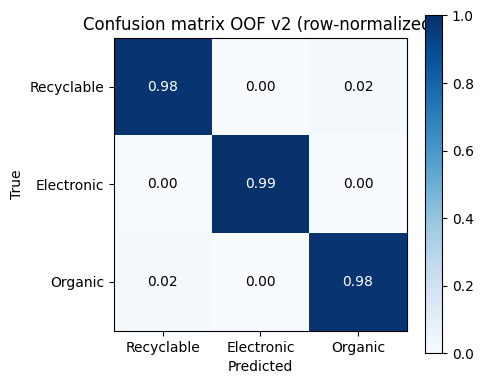

OOF disimpan: /kaggle/working/experiments/experiment_v2_maxvit/oof_predictions.csv


In [21]:
oof_mask = ~np.isnan(oof_probs).any(axis=1)
print(f"OOF tersedia untuk {int(oof_mask.sum())}/{len(train_df)} baris (fold dilatih: {CFG.TRAIN_FOLDS})")
oof_pred = oof_probs[oof_mask].argmax(axis=1)
oof_true = train_df.loc[oof_mask, "label"].to_numpy()

oof_macro_f1 = f1_score(oof_true, oof_pred, average="macro")
oof_per_class = f1_score(oof_true, oof_pred, average=None, labels=list(range(CFG.NUM_CLASSES)))
per_fold = fold_summary_df["val_macro_f1"].to_numpy()
print(f"\nOOF macro F1 (pooled)      : {oof_macro_f1:.4f}")
print(f"Referensi v1 (fold sama)   : {CFG.V1_OOF_MACRO_F1:.4f} | selisih v2-v1: {oof_macro_f1 - CFG.V1_OOF_MACRO_F1:+.4f}")
print(f"Per-fold macro F1          : {[round(v, 4) for v in per_fold]}")
print(f"Mean+-std per-fold macro F1: {per_fold.mean():.4f} +- {per_fold.std():.4f}")
print()
print(classification_report(oof_true, oof_pred,
                            labels=list(range(CFG.NUM_CLASSES)),
                            target_names=[CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)], digits=4))

cm = confusion_matrix(oof_true, oof_pred, labels=list(range(CFG.NUM_CLASSES)), normalize="true")
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
tick_names = [CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)]
ax.set_xticks(range(CFG.NUM_CLASSES), tick_names)
ax.set_yticks(range(CFG.NUM_CLASSES), tick_names)
for i in range(CFG.NUM_CLASSES):
    for j in range(CFG.NUM_CLASSES):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix OOF v2 (row-normalized)")
plt.colorbar(im)
plt.tight_layout()
plt.show()

oof_out = train_df.loc[oof_mask, ["relpath", "class_name", "label", "fold"]].copy()
oof_out["pred"] = oof_pred
for i in range(CFG.NUM_CLASSES):
    oof_out[f"prob_{i}"] = oof_probs[oof_mask, i]
oof_out.to_csv(CFG.EXP_DIR / "oof_predictions.csv", index=False)
print("OOF disimpan:", CFG.EXP_DIR / "oof_predictions.csv")

In [22]:
# Catat hasil ke experiments/EXPERIMENTS_LOG.md (append-only, entry lama tidak boleh ditimpa)
NOTES = ("Experiment v2: MaxViT-Base rw in12k->in1k (timm maxvit_rmlp_base_rw_224.sw_in12k_ft_in1k, "
         "pretrained publik, tidak pernah dilatih pada data kompetisi), full fine-tune 224px, "
         "fold IDENTIK v1 (StratifiedKFold seed 42, audit near-dup verdict NEGLIGIBLE), "
         "FocalLoss+WeightedSampler identik v1, tambahan mixup/cutmix GPU (p=0.5, alpha 0.2/1.0), "
         "greedy model soup per fold (top-4 checkpoint, seleksi val macro F1).")

_soup_desc = ", ".join(f"fold{r.fold}: {r.winner} (single {r.best_single_no_tta:.4f} -> soup {r.soup_no_tta:.4f})"
                       for r in fold_summary_df.itertuples())
entry = f"""
## {CFG.RUN_NAME} - {date.today().isoformat()}

- Backbone            : {CFG.MODEL_ID} (timm), full fine-tune, img {CFG.IMG_SIZE}
- Data                : {len(train_df)} gambar train setelah cleaning | fold dilatih: {CFG.TRAIN_FOLDS}
- Macro F1 per fold   : {", ".join(f"fold{r.fold}={r.val_macro_f1:.4f}" for r in fold_summary_df.itertuples())}
- TTA ablation (val)  : {", ".join(f"fold{r.fold}: tanpa-TTA={r.val_macro_f1_no_tta:.4f} / TTA={r.val_macro_f1_tta:.4f}" for r in fold_summary_df.itertuples())}
- Soup per fold       : {_soup_desc}
- Mean+-std per fold  : {per_fold.mean():.4f} +- {per_fold.std():.4f}
- OOF macro F1 pooled : {oof_macro_f1:.4f} (referensi v1: {CFG.V1_OOF_MACRO_F1:.4f}, selisih {oof_macro_f1 - CFG.V1_OOF_MACRO_F1:+.4f})
- Per-class F1 (OOF)  : {", ".join(f"{CFG.LABEL_NAMES[i]}={oof_per_class[i]:.4f}" for i in range(CFG.NUM_CLASSES))}
- Catatan             : {NOTES}
"""
print(entry)
if CFG.SMOKE_TEST:
    print(">> SMOKE_TEST aktif: entry TIDAK ditulis ke log (bukan hasil eksperimen valid).")
else:
    CFG.LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
    with open(CFG.LOG_PATH, "a", encoding="utf-8") as f:
        f.write(entry)
    print(">> Entry ditambahkan (append) ke", CFG.LOG_PATH)
    if CFG.ON_KAGGLE:
        print(">> Di Kaggle log ini ada di /kaggle/working, unduh lalu merge ke experiments/EXPERIMENTS_LOG.md repo lokal.")


## experiment_v2_maxvit - 2026-07-13

- Backbone            : maxvit_rmlp_base_rw_224.sw_in12k_ft_in1k (timm), full fine-tune, img 224
- Data                : 26464 gambar train setelah cleaning | fold dilatih: [0, 1, 2, 3, 4]
- Macro F1 per fold   : fold0=0.9824, fold1=0.9848, fold2=0.9830, fold3=0.9843, fold4=0.9805
- TTA ablation (val)  : fold0: tanpa-TTA=0.9827 / TTA=0.9824, fold1: tanpa-TTA=0.9847 / TTA=0.9848, fold2: tanpa-TTA=0.9828 / TTA=0.9830, fold3: tanpa-TTA=0.9833 / TTA=0.9843, fold4: tanpa-TTA=0.9813 / TTA=0.9805
- Soup per fold       : fold0: soup(e[9, 10]) (single 0.9824 -> soup 0.9827), fold1: soup(e[9, 10]) (single 0.9842 -> soup 0.9847), fold2: soup(e[7, 8, 9]) (single 0.9823 -> soup 0.9828), fold3: soup(e[9, 10]) (single 0.9832 -> soup 0.9833), fold4: soup(e[7, 9, 10]) (single 0.9812 -> soup 0.9813)
- Mean+-std per fold  : 0.9830 +- 0.0015
- OOF macro F1 pooled : 0.9830 (referensi v1: 0.9818, selisih +0.0012)
- Per-class F1 (OOF)  : Recyclable=0.9766, Electronic=0.

## 8. Ensemble OOF dengan v1 (opsional; hanya bila artefak v1 di-attach)

Bobot ensemble dipilih dari **OOF train saja** (legal; data test tidak disentuh). Sweep `w` untuk `w * probs_v1 + (1-w) * probs_v2`, laporan macro F1 per bobot. Sah HANYA karena fold split identik (di-assert). Kalau `oof_predictions.csv` v1 tidak ditemukan (notebook v1 belum di-attach sebagai input), bagian ini di-skip dengan instruksi.

**Aturan keputusan submission (runbook)**: kandidat (v2 tunggal atau ensemble) layak submit hanya bila OOF macro F1 >= acuan + 0.002. Keputusan menekan tombol submit tetap di tangan user.

In [23]:
ENSEMBLE_W_V1 = None  # bobot v1 hasil seleksi OOF; None = ensemble tidak dievaluasi
_v1_oof_cands = [p for p in glob.glob("/kaggle/input/**/oof_predictions.csv", recursive=True) if CFG.V1_RUN_NAME in p] + \
    [str(CFG.OUTPUT_ROOT / "experiments" / CFG.V1_RUN_NAME / "oof_predictions.csv")]
_v1_oof_path = next((p for p in _v1_oof_cands if Path(p).is_file()), None)

if CFG.SMOKE_TEST:
    print("SMOKE_TEST: evaluasi ensemble dilewati (OOF subset tidak bermakna).")
elif not CFG.ENSEMBLE_WITH_V1:
    print("CFG.ENSEMBLE_WITH_V1=False: evaluasi ensemble dilewati.")
elif _v1_oof_path is None:
    print("oof_predictions.csv v1 TIDAK ditemukan; evaluasi ensemble dilewati.")
    print("Cara mengaktifkan: Add Input -> Your Work -> notebook baseline v1 (versi run 5-fold sukses),")
    print(f"sehingga tersedia /kaggle/input/<slug>/experiments/{CFG.V1_RUN_NAME}/oof_predictions.csv")
else:
    a = pd.read_csv(_v1_oof_path)
    b = oof_out
    assert len(a) >= 26000 and len(b) >= 26000, f"OOF belum lengkap: v1={len(a)} v2={len(b)}. Ensemble tidak sah."
    m = a.merge(b, on="relpath", suffixes=("_v1", "_v2"))
    assert len(m) == len(a) == len(b), f"relpath tidak match penuh: join={len(m)} v1={len(a)} v2={len(b)}. STOP."
    assert (m["fold_v1"] == m["fold_v2"]).all(), "FOLD BERBEDA antar model: ensemble OOF TIDAK SAH. STOP."
    assert (m["label_v1"] == m["label_v2"]).all(), "Label tidak konsisten antar OOF. STOP."
    y = m["label_v1"].to_numpy()
    p1 = m[[f"prob_{i}_v1" for i in range(3)]].to_numpy()
    p2 = m[[f"prob_{i}_v2" for i in range(3)]].to_numpy()
    print(f"{'w_v1':>5} {'w_v2':>5} {'macro_f1':>9}")
    best_w, best_f1 = None, -1.0
    for w in np.round(np.arange(0.0, 1.0001, 0.05), 2):
        f1 = f1_score(y, (w * p1 + (1 - w) * p2).argmax(axis=1), average="macro")
        tag = ""
        if f1 > best_f1:
            best_w, best_f1 = float(w), float(f1)
            tag = " <- best"
        print(f"{w:5.2f} {1 - w:5.2f} {f1:9.4f}{tag}")
    f1_v1 = f1_score(y, p1.argmax(axis=1), average="macro")
    f1_v2 = f1_score(y, p2.argmax(axis=1), average="macro")
    print(f"\nv1 saja: {f1_v1:.4f} | v2 saja: {f1_v2:.4f} | ensemble terbaik: w_v1={best_w:.2f} -> {best_f1:.4f}")
    print(f"Kenaikan vs kandidat tunggal terbaik: {best_f1 - max(f1_v1, f1_v2):+.4f}")
    if best_f1 >= max(f1_v1, f1_v2) + 0.0005 and 0.0 < best_w < 1.0:
        ENSEMBLE_W_V1 = best_w
        print(f"ENSEMBLE_W_V1 di-set {ENSEMBLE_W_V1}: submission bagian 9 memakai ensemble v1+v2.")
    else:
        print("Gain ensemble tidak meyakinkan (<0.0005) atau bobot degenerate; submission memakai kandidat tunggal terbaik.")
    print("\nAturan runbook: layak submit bila kandidat >= acuan + 0.002 pada OOF fold-identik.")

 w_v1  w_v2  macro_f1
 0.00  1.00    0.9830 <- best
 0.05  0.95    0.9834 <- best
 0.10  0.90    0.9831
 0.15  0.85    0.9831
 0.20  0.80    0.9832
 0.25  0.75    0.9834 <- best
 0.30  0.70    0.9836 <- best
 0.35  0.65    0.9837 <- best
 0.40  0.60    0.9840 <- best
 0.45  0.55    0.9837
 0.50  0.50    0.9836
 0.55  0.45    0.9830
 0.60  0.40    0.9828
 0.65  0.35    0.9826
 0.70  0.30    0.9826
 0.75  0.25    0.9824
 0.80  0.20    0.9821
 0.85  0.15    0.9820
 0.90  0.10    0.9820
 0.95  0.05    0.9820
 1.00  0.00    0.9818

v1 saja: 0.9818 | v2 saja: 0.9830 | ensemble terbaik: w_v1=0.40 -> 0.9840
Kenaikan vs kandidat tunggal terbaik: +0.0010
ENSEMBLE_W_V1 di-set 0.4: submission bagian 9 memakai ensemble v1+v2.

Aturan runbook: layak submit bila kandidat >= acuan + 0.002 pada OOF fold-identik.


## 9. Generate Submission

Aturan (juknis §4-§5): data test **hanya** untuk prediksi akhir; kolom `id,predicted`; kode 0/1/2; urutan id persis template. Nama file memakai **kode kelompok**: `submission_SD2026040000412.csv` (konfirmasi panitia).

**Exact match test->train** (identik v1): 97 file test byte-identik dengan train memakai label train langsung; legal karena murni kesamaan internal dataset kompetisi, tanpa menyentuh training. Near-duplicate test->train yang BUKAN exact **tidak** dipakai (objek bisa berbeda; hanya masuk laporan review, lihat `experiments/near_dup_audit/`).

Prediksi model: mean softmax semua fold v2 + TTA flip; bila `ENSEMBLE_W_V1` terisi (bagian 8) dan checkpoint v1 di-attach, dipakai `w*probs_v1 + (1-w)*probs_v2` dengan pipeline eval per keluarga model (normalisasi ConvNeXt != MaxViT, dua transform terpisah).

In [24]:
ckpt_prefix = "smoke_" if CFG.SMOKE_TEST else ""
ckpt_paths = sorted(CFG.EXP_DIR.glob(f"{ckpt_prefix}fold*_best.pt"))
if not CFG.SMOKE_TEST:
    ckpt_paths = [p for p in ckpt_paths if not p.name.startswith("smoke_")]
assert ckpt_paths, "Tidak ada checkpoint fold, jalankan training dulu"
print("Checkpoint v2 dipakai:", [p.name for p in ckpt_paths])
if len(ckpt_paths) < CFG.N_FOLDS:
    print(f"PERINGATAN: baru {len(ckpt_paths)}/{CFG.N_FOLDS} fold, submission final sebaiknya memakai semua fold.")

test_infer_df = pd.DataFrame({"id": TEMPLATE_ID_ORDER})
test_infer_df["path"] = test_infer_df["id"].map(lambda i: str(test_id_to_path[i]))
assert test_infer_df["path"].notna().all()
if CFG.SMOKE_TEST:
    test_infer_df = test_infer_df.head(CFG.SMOKE_TEST_IMAGES)
    print(f"SMOKE_TEST: inference hanya {len(test_infer_df)} gambar test pertama (cek pipeline).")

# Exact match test->train via sha256 (train_df sudah unik per sha, mixed-label sudah dikeluarkan)
hash_to_label = train_df.set_index("sha256")["label"].to_dict()
relpath_to_hash = test_scan.set_index("relpath")["sha256"].to_dict()
test_infer_df["sha256"] = [relpath_to_hash.get(str(Path(p).relative_to(CFG.DATA_ROOT))) for p in test_infer_df["path"]]
test_infer_df["match_label"] = test_infer_df["sha256"].map(hash_to_label)
matched_mask = test_infer_df["match_label"].notna().to_numpy()
print(f"Exact match test->train: {int(matched_mask.sum())}/{len(test_infer_df)} baris memakai label train langsung")

preds = np.full(len(test_infer_df), -1, dtype=int)
preds[matched_mask] = test_infer_df.loc[matched_mask, "match_label"].astype(int).to_numpy()

unmatched_df = test_infer_df[~matched_mask].reset_index(drop=True)


def infer_mean_probs(ckpt_list, model_builder, expected_model_id, infer_df):
    """Mean softmax lintas checkpoint untuk satu keluarga model; transform eval dari metadata checkpoint."""
    total = np.zeros((len(infer_df), CFG.NUM_CLASSES))
    for cp in ckpt_list:
        ckpt = torch.load(cp, map_location="cpu", weights_only=False)
        assert ckpt["model_id"] == expected_model_id, f"{cp}: model_id {ckpt['model_id']} != {expected_model_id}"
        assert CFG.SMOKE_TEST or not ckpt.get("smoke"), f"{Path(cp).name} berasal dari smoke run"
        _, tf_eval = build_transforms(ckpt["img_size"], tuple(ckpt["mean"]), tuple(ckpt["std"]))
        loader = DataLoader(WasteDataset(infer_df, tf_eval, with_target=False, safe_mode=True,
                                         img_size=ckpt["img_size"], max_decode_side=CFG.MAX_DECODE_SIDE),
                            batch_size=CFG.BATCH_SIZE * 2, shuffle=False, num_workers=CFG.NUM_WORKERS,
                            pin_memory=False,
                            prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,
                            worker_init_fn=worker_init_fn if CFG.NUM_WORKERS > 0 else None)
        model = model_builder()
        model.load_state_dict(ckpt["state_dict"])
        model = maybe_data_parallel(model.to(DEVICE))
        out = run_epoch(model, loader, use_tta=CFG.USE_VAL_TTA, desc=f"infer {Path(cp).stem}")
        total += out["probs"] / len(ckpt_list)
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return total


if len(unmatched_df):
    probs_v2 = infer_mean_probs(ckpt_paths, lambda: timm.create_model(CFG.MODEL_ID, pretrained=False,
                                                                      num_classes=CFG.NUM_CLASSES),
                                CFG.MODEL_ID, unmatched_df)
    final_probs = probs_v2
    _v1_ckpts = sorted(glob.glob(f"/kaggle/input/*/experiments/{CFG.V1_RUN_NAME}/fold*_best.pt"))
    if ENSEMBLE_W_V1 is not None and len(_v1_ckpts) == CFG.N_FOLDS:
        print(f"Ensemble aktif: w_v1={ENSEMBLE_W_V1} | checkpoint v1: {[Path(p).name for p in _v1_ckpts]}")
        probs_v1 = infer_mean_probs(_v1_ckpts, lambda: timm.create_model(CFG.V1_MODEL_ID, pretrained=False,
                                                                         num_classes=CFG.NUM_CLASSES),
                                    CFG.V1_MODEL_ID, unmatched_df)
        final_probs = ENSEMBLE_W_V1 * probs_v1 + (1 - ENSEMBLE_W_V1) * probs_v2
    elif ENSEMBLE_W_V1 is not None:
        print(f"ENSEMBLE_W_V1={ENSEMBLE_W_V1} tapi checkpoint v1 tidak lengkap ({len(_v1_ckpts)}/5): pakai v2 saja.")
    preds[~matched_mask] = final_probs.argmax(axis=1).astype(int)

assert (preds >= 0).all()
test_infer_df["predicted"] = preds
print("\nDistribusi prediksi:")
print(test_infer_df["predicted"].value_counts().rename(index=CFG.LABEL_NAMES).to_string())

Checkpoint v2 dipakai: ['fold0_best.pt', 'fold1_best.pt', 'fold2_best.pt', 'fold3_best.pt', 'fold4_best.pt']
Exact match test->train: 97/1458 baris memakai label train langsung


infer fold0_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold0_best: batch 22/22 (100%) | 1.43s/iter | RSS 6.7GB (delta +0.0GB)


infer fold1_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold1_best: batch 22/22 (100%) | 1.24s/iter | RSS 6.7GB (delta +0.0GB)


...

[hb] infer fold2_best: batch 22/22 (100%) | 1.25s/iter | RSS 6.7GB (delta +0.0GB)


infer fold3_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold3_best: batch 22/22 (100%) | 1.24s/iter | RSS 6.7GB (delta +0.0GB)


infer fold4_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold4_best: batch 22/22 (100%) | 1.25s/iter | RSS 6.7GB (delta +0.0GB)
ENSEMBLE_W_V1=0.4 tapi checkpoint v1 tidak lengkap (0/5): pakai v2 saja.

Distribusi prediksi:
predicted
Organic       733
Recyclable    524
Electronic    201


In [25]:
submission_df = test_infer_df[["id", "predicted"]].copy()

# Verifikasi keras terhadap template SEBELUM menyimpan (juknis §4: format & urutan wajib persis)
ref = template_df.head(len(submission_df)) if CFG.SMOKE_TEST else template_df
assert list(submission_df.columns) == ["id", "predicted"], "Nama/urutan kolom tidak sesuai template"
assert len(submission_df) == len(ref), f"Jumlah baris {len(submission_df)} != template {len(ref)}"
assert (submission_df["id"].to_numpy() == ref["id"].to_numpy()).all(), "Urutan id TIDAK sama dengan template!"
assert submission_df["predicted"].isin([0, 1, 2]).all(), "predicted harus kode numerik 0/1/2"
assert submission_df["predicted"].notna().all()
print("Semua verifikasi format & urutan id LULUS.")

if CFG.SMOKE_TEST:
    print(">> SMOKE_TEST aktif: file submission TIDAK disimpan. Jalankan full run untuk membuat submission.")
else:
    sub_path = CFG.SUBMISSION_DIR / f"submission_{CFG.GROUP_CODE}.csv"
    submission_df.to_csv(sub_path, index=False)
    submission_df.to_csv(CFG.EXP_DIR / sub_path.name, index=False)  # arsip per eksperimen
    print("Submission disimpan:", sub_path)
    print("(nama file memakai KODE KELOMPOK sesuai konfirmasi panitia, bukan nama tim)")
    comp = pd.DataFrame({
        "pred_test_%": (100 * submission_df["predicted"].value_counts(normalize=True)).round(2),
        "train_%": (100 * train_df["label"].value_counts(normalize=True)).round(2),
    }).rename(index=CFG.LABEL_NAMES)
    print("\nDistribusi prediksi test vs train (sanity check):")
    display(comp)
    print("INGAT: maksimal 3 submission; keputusan submit berbasis OOF + ambang runbook (+0.002), oleh user.")

Semua verifikasi format & urutan id LULUS.
Submission disimpan: /kaggle/working/outputs/submission_SD2026040000412.csv
(nama file memakai KODE KELOMPOK sesuai konfirmasi panitia, bukan nama tim)

Distribusi prediksi test vs train (sanity check):


,pred_test_%,train_%
Organic,50.27,47.40
Recyclable,35.94,37.75
Electronic,13.79,14.85


INGAT: maksimal 3 submission; keputusan submit berbasis OOF + ambang runbook (+0.002), oleh user.


## 10. Analisis Error OOF

Adaptasi pola analisis kesalahan findit-v17 untuk klasifikasi sampah: baris OOF dengan disagreement terbesar (margin `p_pred - p_label`) ditampilkan sebagai grid. Dua kegunaan: (1) memetakan pasangan kelas yang masih tertukar; (2) kandidat teratas untuk antrean review label manual (margin tinggi sering = label folder salah, tapi keputusan tetap manusia, tidak ada relabel otomatis).

Total error OOF: 495 baris

Pasangan (true -> pred) terbanyak:
class_name  pred   n  pred_name
   Organic     0 228 Recyclable
Recyclable     2 189    Organic
Recyclable     1  34 Electronic
   Organic     1  21 Electronic
Electronic     0  16 Recyclable
Electronic     2   7    Organic

Top error disimpan: /kaggle/working/experiments/experiment_v2_maxvit/oof_top_errors.csv (input antrean review label manual)


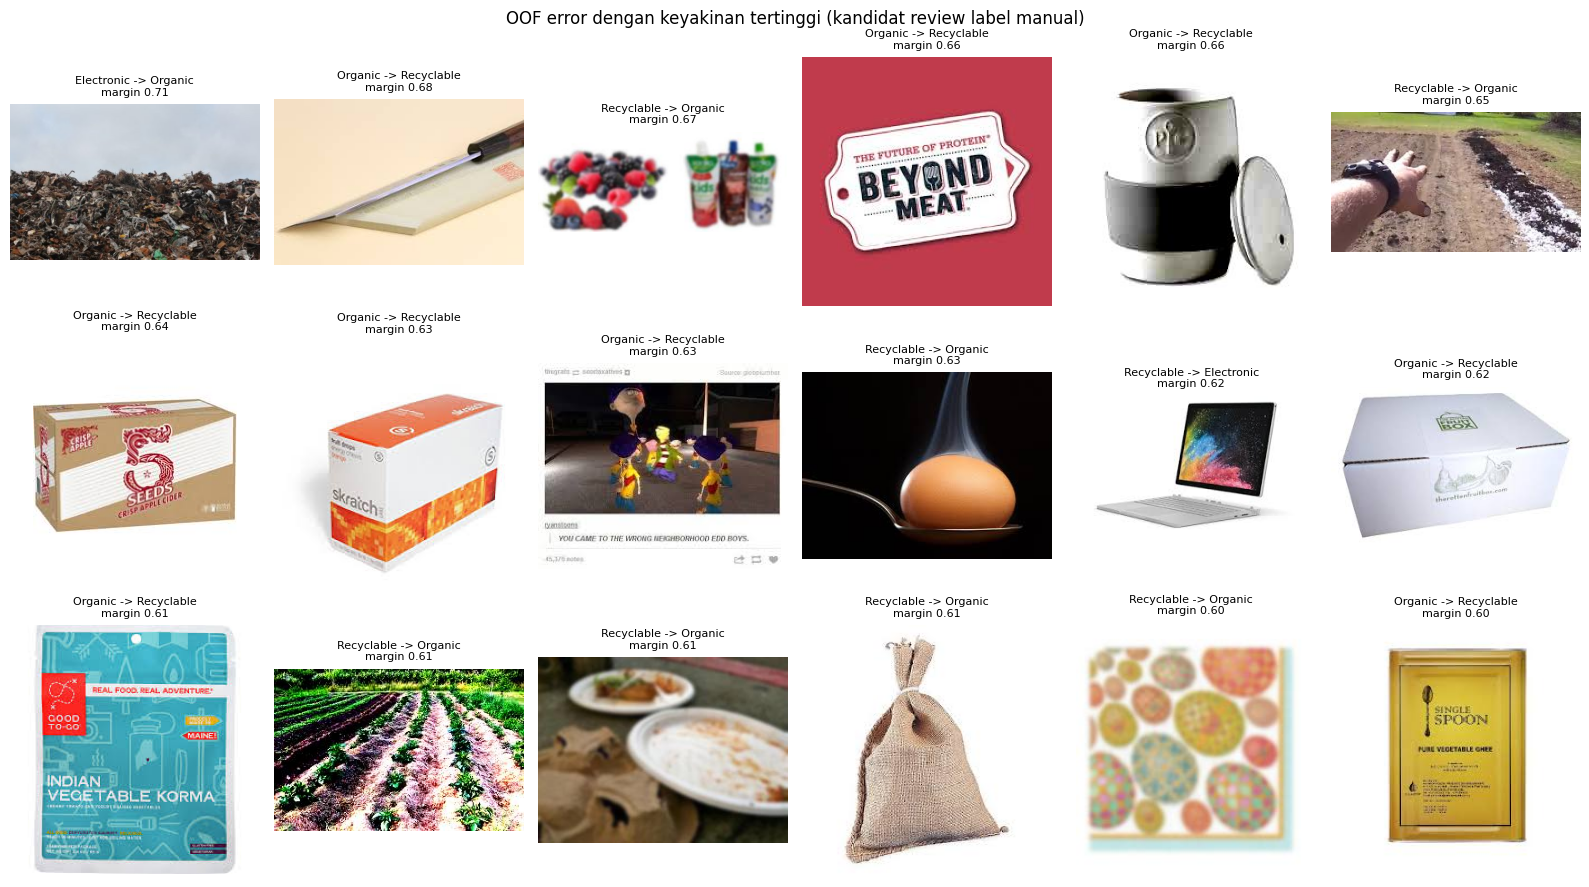

In [26]:
err = oof_out[oof_out["pred"] != oof_out["label"]].copy()
if err.empty:
    print("Tidak ada error OOF (subset smoke terlalu kecil / hasil sempurna).")
else:
    probs_arr = err[[f"prob_{i}" for i in range(CFG.NUM_CLASSES)]].to_numpy()
    err["p_pred"] = probs_arr[np.arange(len(err)), err["pred"].to_numpy()]
    err["p_label"] = probs_arr[np.arange(len(err)), err["label"].to_numpy()]
    err["margin"] = err["p_pred"] - err["p_label"]
    err = err.sort_values("margin", ascending=False)
    print(f"Total error OOF: {len(err)} baris")
    print("\nPasangan (true -> pred) terbanyak:")
    print(err.groupby(["class_name", "pred"]).size().rename("n").reset_index()
          .assign(pred_name=lambda d: d["pred"].map(CFG.LABEL_NAMES))
          .sort_values("n", ascending=False).head(6).to_string(index=False))
    err.head(200).to_csv(CFG.EXP_DIR / "oof_top_errors.csv", index=False)
    print("\nTop error disimpan:", CFG.EXP_DIR / "oof_top_errors.csv (input antrean review label manual)")

    n_show = min(18, len(err))
    path_by_relpath = train_df.set_index("relpath")["path"].to_dict()
    fig, axes = plt.subplots(3, 6, figsize=(16, 9))
    for ax, (_, r) in zip(axes.flat, err.head(n_show).iterrows()):
        try:
            img = Image.open(path_by_relpath[r["relpath"]])
            img.draft("RGB", (512, 512))
            ax.imshow(ImageOps.exif_transpose(img).convert("RGB"))
        except Exception:
            pass
        ax.set_title(f"{r['class_name']} -> {CFG.LABEL_NAMES[int(r['pred'])]}\nmargin {r['margin']:.2f}", fontsize=8)
        ax.axis("off")
    for ax in axes.flat[n_show:]:
        ax.axis("off")
    plt.suptitle("OOF error dengan keyakinan tertinggi (kandidat review label manual)")
    plt.tight_layout()
    plt.show()

> ### Insights
> Kalau error dengan margin tertinggi didominasi gambar yang labelnya memang meragukan secara visual (label folder salah, objek campuran, infografis), perbaikan berikutnya yang paling murah adalah antrean relabel manual, bukan menambah kapasitas model. Kalau sebaliknya didominasi objek valid yang mirip antar kelas (mis. kardus vs ranting), kandidat berikutnya adalah menambah anggota ensemble dengan bias induktif berbeda lagi atau resolusi lebih tinggi untuk detail halus (uji satu fold dulu).

## Catatan Operasional

**Checklist commit Kaggle (run nyata):**
1. `SMOKE_TEST = False`; Internet ON; GPU T4 (single, `USE_DATA_PARALLEL=False`); secret `WANDB_API_KEY` opsional.
2. Opsional tapi disarankan: *Add Input -> Your Work -> notebook baseline v1* (versi run 5-fold sukses 2026-07-05) supaya cross-check fold, evaluasi ensemble OOF, dan submission ensemble aktif otomatis.
3. *Save Version -> Save & Run All (Commit)*.
4. Menit-menit awal yang dipantau: baris `RAM total/available`, `pre-resize SELESAI: 233 dialihkan`, heartbeat `[hb] f0 e1 train: ... s/iter | RSS (delta ...)`.
5. **Proyeksi runtime**: dari `s/iter` epoch pertama, estimasi total = s/iter x 662 batch x 10 epoch x 5 fold + validasi + soup (+- 15%). Kalau proyeksi > 8.5 jam: hentikan, pecah `TRAIN_FOLDS=[0,1,2]` lalu `[3,4]` di dua commit; gabungkan `oof_predictions.csv` kedua run (concat baris; tiap run hanya berisi fold yang dilatih) sebelum evaluasi ensemble.
6. Kriteria sehat: delta RSS mendekati konstan setelah warm-up; kalau naik linear, hentikan dan laporkan (pola debug v1).

**Setelah run selesai**: unduh isi `/kaggle/working` (checkpoint per fold, `folds.csv`, `oof_predictions.csv`, `fold_summary.csv`, `history.csv`, `EXPERIMENTS_LOG.md`, submission), merge entry log ke repo lokal. Keputusan submit mengikuti runbook: kandidat perlu OOF >= acuan + 0.002; file yang di-upload wajib lolos verifikasi format; arsipkan byte yang persis terkirim.

**Rerun setelah manual relabeling**: label dibaca dari struktur folder tiap run; kalau relabel diterapkan (antrean `duplicates_mixed_label_review.csv` + `near_dup_mixed_label_review.csv`), dataset Kaggle harus di-update ke versi baru dan fold di-recompute (OOF lama tidak comparable, catat di log).

## Referensi

- Sayem et al. 2025, *Waste classification and detection on WaRP* (NCA s00521-024-10855-2): MaxViT-T 82.19% vs ConvNeXt 80.21% pada data sampah heterogen; fusi CNN+ViT +0.92.
- arXiv 2603.02181: greedy/uniform model soups pada fine-tune data noisy, gain +0.4-0.9 acc dengan biaya inferensi satu model.
- arXiv 2602.10500: benchmark Garbage Dataset di Kaggle T4; arsitektur >> resolusi input (384px gain <1%, kadang negatif).
- arXiv 2606.25784 (S2-FracMix): pada backbone pretrained kuat gain vs mixup biasa hilang; dasar memilih mixup/cutmix standar.
- arXiv 2604.09697, 2507.01347: TTA tidak selalu membantu; divalidasi per fold (ablation).
- arXiv 2407.05528, 2410.07689: deteksi label-noise otomatis tidak boleh auto-drop/relabel; antrean review manual.
- Audit near-duplicate lokal 2026-07-12: `experiments/near_dup_audit/near_dup_audit_report.md` (verdict NEGLIGIBLE, batas atas inflasi OOF 0.0007).